In [1]:
# Setup: run this first, every session
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from pathlib import Path

try:
    import duckdb
    print("✓ packages")
except ModuleNotFoundError:
    print("✗ duckdb is missing: in a new cell run   %pip install duckdb")
    print("  then Kernel > Restart Kernel, and run this cell again.")

sns.set_theme()
pd.set_option("display.max_columns", None)

# File locations: change csv_path if you moved the CSV
csv_path = Path("hmda_east_coast_2023_2025.csv")
db_path = Path("hmda.duckdb")            # saved next to this notebook

✓ packages


In [2]:
# Check whether the CSV is complete and every row has the right number of columns
def check_csv(path, expected_rows=6_226_208, show=5):
    path = Path(path)
    if not path.exists():
        print(f"✗ File not found: {path.resolve()}")
        return False

    print(f"Checking {path.name} ({path.stat().st_size / 1e9:.2f} GB)...")
    n_rows, n_bad, bad_examples, last_line = 0, 0, [], b""

    with open(path, "rb") as f:
        header = f.readline()
        n_cols = header.count(b",") + 1
        for line_no, line in enumerate(f, start=2):   # header is line 1
            n_rows += 1
            found = line.count(b",") + 1
            if found != n_cols:
                n_bad += 1
                if len(bad_examples) < show:
                    bad_examples.append((line_no, found, line[:80]))
            last_line = line

    ends_cleanly = last_line.endswith(b"\n")

    print(f"Columns in header:   {n_cols}")
    print(f"Data rows:           {n_rows:,}  (expected {expected_rows:,})")
    print(f"Rows with wrong column count: {n_bad:,}")
    for line_no, found, text in bad_examples:
        print(f"   line {line_no:,}: {found} columns -> {text.decode(errors='replace')}...")
    print(f"File ends with a line break: {ends_cleanly}")

    ok = n_bad == 0 and ends_cleanly and n_rows == expected_rows
    if ok:
        print("✔ File looks complete and intact.")
    elif not ends_cleanly and n_bad == 1 and bad_examples[0][0] == n_rows + 1:
        print("✗ File is cut off (truncated): the last row is incomplete. Copy it again.")
    else:
        print("✗ File has problems: see the rows listed above.")
    return ok

check_csv(csv_path)

Checking hmda_east_coast_2023_2025.csv (2.40 GB)...
Columns in header:   99
Data rows:           6,226,208  (expected 6,226,208)
Rows with wrong column count: 0
File ends with a line break: True
✔ File looks complete and intact.


True

In [3]:
# # con.close()   # Windows won't let you delete the file while it's open
# for f in [Path("hmda.duckdb"), Path("hmda.duckdb.wal")]:
#     f.unlink(missing_ok=True)
# print("Old database removed:", not Path("hmda.duckdb").exists())

In [4]:
# Open the HMDA database
# the raw data
first_run = not db_path.exists()
con = duckdb.connect(str(db_path))
con.sql("SET memory_limit = '4GB'")      # leave RAM for the rest of your Mac

# First run only: load the CSV into the database (a few minutes, once)
if first_run:
    if not csv_path.exists():
        con.close()
        db_path.unlink()                 # remove the empty database just created
        raise FileNotFoundError(f"Can't find the CSV at {csv_path} - fix csv_path in Cell 1.")
    print("First run: loading the CSV into hmda.duckdb (a few minutes)...")
    con.sql(f"""
        CREATE TABLE hmda_raw AS
        SELECT * FROM read_csv_auto('{csv_path}', all_varchar = true)
    """)

# Clean view with numbers converted ("Exempt"/"NA" become NULL)
con.sql("""
    CREATE OR REPLACE VIEW hmda AS
    SELECT activity_year,
           state_code,
           derived_race,
           derived_sex,
           TRY_CAST(rate_spread         AS DOUBLE) AS rate_spread,
           TRY_CAST(income              AS DOUBLE) AS income,        -- in $ thousands
           TRY_CAST(loan_amount         AS DOUBLE) AS loan_amount,
           TRY_CAST(loan_to_value_ratio AS DOUBLE) AS loan_to_value_ratio,
           debt_to_income_ratio,                                     -- text bands, e.g. '30%-<36%'
           loan_type,
           loan_purpose
    FROM hmda_raw
""")

n_rows = con.sql("SELECT COUNT(*) AS n FROM hmda_raw").df()["n"][0]
print(f"✓ hmda.duckdb ready: {n_rows:,} rows")

✓ hmda.duckdb ready: 6,226,208 rows


In [5]:
con.sql("SELECT * FROM hmda_raw LIMIT 10").df()

,activity_year,lei,derived_msa-md,state_code,county_code,census_tract,conforming_loan_limit,derived_loan_product_type,derived_dwelling_category,derived_ethnicity,derived_race,derived_sex,action_taken,purchaser_type,preapproval,loan_type,loan_purpose,lien_status,reverse_mortgage,open-end_line_of_credit,business_or_commercial_purpose,loan_amount,loan_to_value_ratio,interest_rate,rate_spread,hoepa_status,total_loan_costs,total_points_and_fees,origination_charges,discount_points,lender_credits,loan_term,prepayment_penalty_term,intro_rate_period,negative_amortization,interest_only_payment,balloon_payment,other_nonamortizing_features,property_value,construction_method,occupancy_type,manufactured_home_secured_property_type,manufactured_home_land_property_interest,total_units,multifamily_affordable_units,income,debt_to_income_ratio,applicant_credit_score_type,co-applicant_credit_score_type,applicant_ethnicity-1,applicant_ethnicity-2,applicant_ethnicity-3,applicant_ethnicity-4,applicant_ethnicity-5,co-applicant_ethnicity-1,co-applicant_ethnicity-2,co-applicant_ethnicity-3,co-applicant_ethnicity-4,co-applicant_ethnicity-5,applicant_ethnicity_observed,co-applicant_ethnicity_observed,applicant_race-1,applicant_race-2,applicant_race-3,applicant_race-4,applicant_race-5,co-applicant_race-1,co-applicant_race-2,co-applicant_race-3,co-applicant_race-4,co-applicant_race-5,applicant_race_observed,co-applicant_race_observed,applicant_sex,co-applicant_sex,applicant_sex_observed,co-applicant_sex_observed,applicant_age,co-applicant_age,applicant_age_above_62,co-applicant_age_above_62,submission_of_application,initially_payable_to_institution,aus-1,aus-2,aus-3,aus-4,aus-5,denial_reason-1,denial_reason-2,denial_reason-3,denial_reason-4,tract_population,tract_minority_population_percent,ffiec_msa_md_median_family_income,tract_to_msa_income_percentage,tract_owner_occupied_units,tract_one_to_four_family_homes,tract_median_age_of_housing_units
0,2023,549300VZVN841I2ILS84,38860,ME,23023,23023970301,C,VA:First Lien,Single Family (1-4 Units):Site-Built,Hispanic or Latino,Joint,Male,1,2,2,3,1,1,2,2,2,405000.0,100.00000,6.750,0.099,2,9741.30,NA,7184.30,5694.30,10.95,360,NA,NA,2,2,2,2,405000,1,1,3,5,1,NA,151,39,3,9,1,12,None,None,None,1,12,None,None,None,2,2,3,5,None,None,None,3,5,None,None,None,2,2,1,1,2,2,25-34,<25,No,No,1,1,1,None,None,None,None,10,None,None,None,5192,7.47,108500,102.88,1471,1998,27
1,2023,549300VZVN841I2ILS84,38860,ME,23031,23031036002,C,Conventional:First Lien,Single Family (1-4 Units):Site-Built,Not Hispanic or Latino,White,Male,1,3,2,1,1,1,2,2,2,565000.0,80.00000,6.950,0.379,2,3644.50,NA,1890.00,NaN,4.25,360,NA,NA,2,2,2,2,705000,1,1,3,5,1,NA,236,20%-<30%,2,10,2,NaN,None,None,None,5,NaN,None,None,None,2,4,5,NaN,None,None,None,8,NaN,None,None,None,2,4,1,5,2,4,25-34,9999,No,NA,1,1,2,None,None,None,None,10,None,None,None,6260,7.65,108500,150.67,2086,2704,44
2,2023,549300VZVN841I2ILS84,99999,ME,23009,23009965300,C,Conventional:First Lien,Single Family (1-4 Units):Site-Built,Not Hispanic or Latino,White,Female,1,1,2,1,1,1,2,2,2,225000.0,95.00000,6.875,0.476,2,6146.40,NA,4180.40,2690.40,45.00,360,NA,NA,2,2,2,2,245000,1,1,3,5,1,NA,87,40,2,10,2,NaN,None,None,None,5,NaN,None,None,None,2,4,5,NaN,None,None,None,8,NaN,None,None,None,2,4,2,5,2,4,45-54,9999,No,NA,1,1,1,None,None,None,None,10,None,None,None,4944,6.78,80600,83.37,1525,2328,48
3,2023,549300VZVN841I2ILS84,99999,ME,23013,23013970800,C,Conventional:First Lien,Single Family (1-4 Units):Site-Built,Not Hispanic or Latino,White,Male,1,5,2,1,1,1,2,2,1,315000.0,75.00000,8.750,NA,3,NA,NA,NA,NA,NA,360,NA,NA,2,2,2,2,425000,1,3,3,5,1,NA,NA,NA,1,9,2,NaN,None,None,None,2,NaN,None,None,None,2,2,5,NaN,None,None,None,5,NaN,None,None,None,2,2,1,1,2,2,25-34,25-34,No,No,1,1,1,None,None,None,None,10,None,None,None,3015,5.8,80600,113.07,1047,1985,45
4,2023,549300VZVN841I2ILS84,38860,ME,23005,23005002902,C,FHA:First Lien,Single Family (1-4 Units):Site-Built,Not Hispanic or Latino,White,Male,1,2,2,2,32,1,2,2,2,215

In [6]:
# making sure that we filter the ones that meet the requirement
query = """
CREATE OR REPLACE TABLE clean_full_hmda AS
SELECT *
FROM hmda_raw
WHERE loan_purpose == '1' AND lien_status == '1' AND occupancy_type == '1' AND TRY_CAST(loan_term AS INTEGER) = 360 AND action_taken = '1' 
  AND reverse_mortgage = '2' AND business_or_commercial_purpose = '2' 
  AND balloon_payment = '2' AND interest_only_payment = '2' 
  AND negative_amortization = '2' 
"""
con.sql(query)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

CountBIGINT
2688857


In [7]:
#  convert sql instance to dataframe
filtered_data = con.sql("SELECT * FROM clean_full_hmda").df()
print(f"{len(filtered_data):,} rows × {filtered_data.shape[1]} columns")
filtered_data.head()

2,688,857 rows × 99 columns


,activity_year,lei,derived_msa-md,state_code,county_code,census_tract,conforming_loan_limit,derived_loan_product_type,derived_dwelling_category,derived_ethnicity,derived_race,derived_sex,action_taken,purchaser_type,preapproval,loan_type,loan_purpose,lien_status,reverse_mortgage,open-end_line_of_credit,business_or_commercial_purpose,loan_amount,loan_to_value_ratio,interest_rate,rate_spread,hoepa_status,total_loan_costs,total_points_and_fees,origination_charges,discount_points,lender_credits,loan_term,prepayment_penalty_term,intro_rate_period,negative_amortization,interest_only_payment,balloon_payment,other_nonamortizing_features,property_value,construction_method,occupancy_type,manufactured_home_secured_property_type,manufactured_home_land_property_interest,total_units,multifamily_affordable_units,income,debt_to_income_ratio,applicant_credit_score_type,co-applicant_credit_score_type,applicant_ethnicity-1,applicant_ethnicity-2,applicant_ethnicity-3,applicant_ethnicity-4,applicant_ethnicity-5,co-applicant_ethnicity-1,co-applicant_ethnicity-2,co-applicant_ethnicity-3,co-applicant_ethnicity-4,co-applicant_ethnicity-5,applicant_ethnicity_observed,co-applicant_ethnicity_observed,applicant_race-1,applicant_race-2,applicant_race-3,applicant_race-4,applicant_race-5,co-applicant_race-1,co-applicant_race-2,co-applicant_race-3,co-applicant_race-4,co-applicant_race-5,applicant_race_observed,co-applicant_race_observed,applicant_sex,co-applicant_sex,applicant_sex_observed,co-applicant_sex_observed,applicant_age,co-applicant_age,applicant_age_above_62,co-applicant_age_above_62,submission_of_application,initially_payable_to_institution,aus-1,aus-2,aus-3,aus-4,aus-5,denial_reason-1,denial_reason-2,denial_reason-3,denial_reason-4,tract_population,tract_minority_population_percent,ffiec_msa_md_median_family_income,tract_to_msa_income_percentage,tract_owner_occupied_units,tract_one_to_four_family_homes,tract_median_age_of_housing_units
0,2023,549300VZVN841I2ILS84,38860,ME,23023,23023970301,C,VA:First Lien,Single Family (1-4 Units):Site-Built,Hispanic or Latino,Joint,Male,1,2,2,3,1,1,2,2,2,405000.0,100.00000,6.750,0.099,2,9741.30,NA,7184.30,5694.30,10.95,360,NA,NA,2,2,2,2,405000,1,1,3,5,1,NA,151,39,3,9,1,12,NaN,NaN,NaN,1,12,NaN,NaN,NaN,2,2,3,5,NaN,NaN,NaN,3,5,NaN,NaN,NaN,2,2,1,1,2,2,25-34,<25,No,No,1,1,1,NaN,NaN,NaN,NaN,10,None,None,None,5192,7.47,108500,102.88,1471,1998,27
1,2023,549300VZVN841I2ILS84,38860,ME,23031,23031036002,C,Conventional:First Lien,Single Family (1-4 Units):Site-Built,Not Hispanic or Latino,White,Male,1,3,2,1,1,1,2,2,2,565000.0,80.00000,6.950,0.379,2,3644.50,NA,1890.00,NaN,4.25,360,NA,NA,2,2,2,2,705000,1,1,3,5,1,NA,236,20%-<30%,2,10,2,NaN,NaN,NaN,NaN,5,NaN,NaN,NaN,NaN,2,4,5,NaN,NaN,NaN,NaN,8,NaN,NaN,NaN,NaN,2,4,1,5,2,4,25-34,9999,No,NA,1,1,2,NaN,NaN,NaN,NaN,10,None,None,None,6260,7.65,108500,150.67,2086,2704,44
2,2023,549300VZVN841I2ILS84,99999,ME,23009,23009965300,C,Conventional:First Lien,Single Family (1-4 Units):Site-Built,Not Hispanic or Latino,White,Female,1,1,2,1,1,1,2,2,2,225000.0,95.00000,6.875,0.476,2,6146.40,NA,4180.40,2690.40,45.00,360,NA,NA,2,2,2,2,245000,1,1,3,5,1,NA,87,40,2,10,2,NaN,NaN,NaN,NaN,5,NaN,NaN,NaN,NaN,2,4,5,NaN,NaN,NaN,NaN,8,NaN,NaN,NaN,NaN,2,4,2,5,2,4,45-54,9999,No,NA,1,1,1,NaN,NaN,NaN,NaN,10,None,None,None,4944,6.78,80600,83.37,1525,2328,48
3,2023,549300VZVN841I2ILS84,99999,ME,23015,23015975800,C,Conventional:First Lien,Single Family (1-4 Units):Site-Built,Not Hispanic or Latino,White,Male,1,1,2,1,1,1,2,2,2,365000.0,70.00000,6.950,0.316,2,5400.48,NA,2140.48,650.48,NaN,360,NA,NA,2,2,2,2,525000,1,1,3,5,1,NA,393,<20%,2,10,2,NaN,NaN,NaN,NaN,5,NaN,NaN,NaN,NaN,2,4,5,NaN,NaN,NaN,NaN,8,NaN,NaN,NaN,NaN,2,4,1,5,2,4,55-64,9999,No,NA,1,1,1,NaN,NaN,NaN,NaN,10,None,None,None,3003,5.59,80600,105.24,1195,2698,40
4,2023,5493000JBDASEOSXCI67,38860,ME,23031,23031020002,C,Conventional:First Lien,Single Family (1-4 Units):Site-Built,Not Hispanic or Latino,White,Joint,1,0,2,1,1,1,2,2,2,545000.0,90.0,6.0,-1.059,2,3784.75,N

In [8]:
# Keep the single family rows
filtered_data = filtered_data[filtered_data["derived_dwelling_category"] == "Single Family (1-4 Units):Site-Built"]

filtered_data = filtered_data[filtered_data["intro_rate_period"] == "NA"]
print(f"{len(filtered_data):,} rows kept")

2,441,578 rows kept


In [9]:
cols = ["activity_year", "lei", "loan_to_value_ratio", "derived_msa-md", "state_code", "county_code",
        "conforming_loan_limit", "derived_ethnicity", "derived_race", "derived_sex",
        "preapproval", "loan_type", "loan_purpose", "loan_amount", "interest_rate",
        "rate_spread", "discount_points", "lender_credits", "loan_term",
        "intro_rate_period", "property_value", "applicant_age", "income",
        "debt_to_income_ratio", "aus-1", "tract_to_msa_income_percentage"]

selected_data = filtered_data[cols].copy()
selected_data = selected_data.rename(columns={"aus-1": "aus", "derived_msa-md": "msa_md"})

print(f"{len(selected_data):,} rows × {selected_data.shape[1]} columns")

2,441,578 rows × 26 columns


# Data Cleaning


In [10]:
df = selected_data.copy()

# --- Quantitative columns -> numbers ("NA", "Exempt" become NaN) ---
num_cols = ["loan_amount",  "loan_to_value_ratio", "interest_rate", "rate_spread", "discount_points", "lender_credits",
            "loan_term", "property_value", "income",
            "tract_to_msa_income_percentage"]
df[num_cols] = df[num_cols].apply(pd.to_numeric, errors="coerce")

# Zeros that can't be real -> missing
for col in ["income", "loan_amount", "property_value", "interest_rate", "loan_term"]:
    df.loc[df[col] <= 0, col] = np.nan

# --- Categorical columns -> text, with "not available" codes as missing ---
cat_cols = ["activity_year", "lei", "msa_md", "state_code", "county_code",
            "conforming_loan_limit", "derived_ethnicity", "derived_race", "derived_sex",
            "preapproval", "loan_type", "loan_purpose", "aus",
            "applicant_age", "debt_to_income_ratio"]
df[cat_cols] = df[cat_cols].astype("string").replace({"NA": pd.NA, "Exempt": pd.NA, "8888": pd.NA})

# Readable labels for the coded columns (HMDA codes)
df["loan_type"] = df["loan_type"].map({"1": "Conventional", "2": "FHA", "3": "VA", "4": "USDA"})
df["loan_purpose"] = df["loan_purpose"].map({"1": "Purchase", "2": "Home improvement",
                                             "31": "Refinance", "32": "Cash-out refinance",
                                             "4": "Other", "5": "Not applicable"})
df["preapproval"] = df["preapproval"].map({"1": "Requested", "2": "Not requested"})
df["aus"] = df["aus"].map({"1": "Desktop Underwriter", "2": "Loan Product Advisor",
                           "3": "TOTAL Scorecard", "4": "GUS", "5": "Other",
                           "6": "Not applicable", "7": "Internal proprietary",
                           "1111": "Exempt"})

# --- Ordered categories ---
# Debt-to-income: HMDA mixes bands with single values 36-49, so group the single values into bands
def dti_band(v):
    if pd.isna(v):
        return pd.NA
    if v.isdigit():
        return "36%-<43%" if int(v) < 43 else "43%-<50%"
    return v

df["debt_to_income_ratio"] = df["debt_to_income_ratio"].map(dti_band)

dti_order = ["<20%", "20%-<30%", "30%-<36%", "36%-<43%", "43%-<50%", "50%-60%", ">60%"]
age_order = ["<25", "25-34", "35-44", "45-54", "55-64", "65-74", ">74"]
df["debt_to_income_ratio"] = df["debt_to_income_ratio"].astype(pd.CategoricalDtype(dti_order, ordered=True))
df["applicant_age"] = df["applicant_age"].astype(pd.CategoricalDtype(age_order, ordered=True))

# Remaining categorical columns -> category (also saves a lot of memory)
other_cats = [c for c in cat_cols if c not in ["debt_to_income_ratio", "applicant_age"]]
df[other_cats] = df[other_cats].astype("category")

df.info()

<class 'pandas.DataFrame'>
Index: 2441578 entries, 0 to 2688856
Data columns (total 26 columns):
 #   Column                          Dtype   
---  ------                          -----   
 0   activity_year                   category
 1   lei                             category
 2   loan_to_value_ratio             float64 
 3   msa_md                          category
 4   state_code                      category
 5   county_code                     category
 6   conforming_loan_limit           category
 7   derived_ethnicity               category
 8   derived_race                    category
 9   derived_sex                     category
 10  preapproval                     category
 11  loan_type                       category
 12  loan_purpose                    category
 13  loan_amount                     float64 
 14  interest_rate                   float64 
 15  rate_spread                     float64 
 16  discount_points                 float64 
 17  lender_credits          

# check summary table

In [11]:
# Summary of the quantitative columns: total rows, missing, min, quartiles, max, mean
summary = df[num_cols].describe().T
summary["rows"] = len(df)                                      # total rows, same for every column
summary["missing"] = df[num_cols].isna().sum()
summary["missing_pct"] = (summary["missing"] / len(df) * 100).round(2)

summary = summary[["rows", "missing", "missing_pct", "min", "25%", "50%", "75%", "max", "mean"]]
pd.set_option("display.float_format", "{:,.2f}".format)
summary

,rows,missing,missing_pct,min,25%,50%,75%,max,mean
loan_amount,2441578,0,0.00,"5,000.00","255,000.00","345,000.00","475,000.00","33,955,000.00","389,036.87"
loan_to_value_ratio,2441578,71405,2.92,1.00,80.00,90.00,96.50,403.42,85.16
interest_rate,2441578,747,0.03,0.00,6.12,6.50,6.88,20.00,6.50
rate_spread,2441578,15303,0.63,-508.00,-0.23,0.16,0.57,"2,402.00",0.16
discount_points,2441578,1024431,41.96,0.00,"1,336.46","3,026.65","5,732.37","522,500.00","4,288.77"
lender_credits,2441578,1583874,64.87,0.01,79.00,515.07,"2,000.00","368,419.44","1,682.23"
loan_term,2441578,0,0.00,360.00,360.00,360.00,360.00,360.00,360.00
property_value,2441578,5769,0.24,"5,000.00","295,000.00","395,000.00","565,000.00","2,147,483,647.00","475,548.93"
income,2441578,17960,0.74,1.00,80.00,114.00,167.00,"476,447.00",154.48
tract_to_msa_income_percentage,2441578,0,0.00,0.00,83.00,104.00,129.00,412.09,108.81


# loan_amount

/var/folders/5l/qq113gg93c53y9n3jjtzg9dm0000gn/T/ipykernel_17573/112994581.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(s, vert=False, whis=1.5)


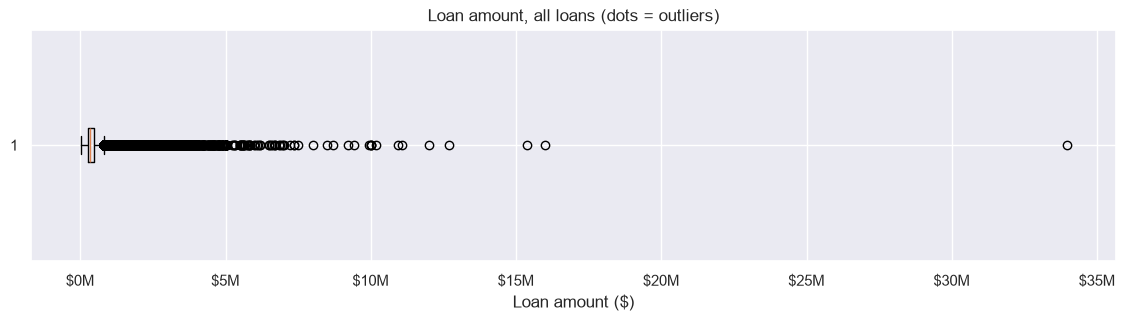

IQR rule: outliers are below $-75,000 or above $805,000
Outliers: 79,369 loans (3.25%)
Over $   1,000,000:   42,500 loans (1.741%)
Over $   2,000,000:    3,853 loans (0.158%)
Over $   5,000,000:       82 loans (0.003%)
Over $  10,000,000:       10 loans (0.000%)


In [12]:
# Outliers in loan_amount: box plot of ALL loans + counts
s = df["loan_amount"]

fig, ax = plt.subplots(figsize=(14, 3))
ax.boxplot(s, vert=False, whis=1.5)
ax.set_xlabel("Loan amount ($)")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"${x/1e6:,.0f}M"))
ax.set_title("Loan amount, all loans (dots = outliers)")
plt.show()

# Outlier rule used by the box plot (IQR rule)
q1, q3 = s.quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
n_out = ((s < low) | (s > high)).sum()
print(f"IQR rule: outliers are below ${low:,.0f} or above ${high:,.0f}")
print(f"Outliers: {n_out:,} loans ({n_out / len(s) * 100:.2f}%)")

# How many loans are above different sizes
for t in [1_000_000, 2_000_000, 5_000_000, 10_000_000]:
    n = (s > t).sum()
    print(f"Over ${t:>12,.0f}: {n:>8,} loans ({n / len(s) * 100:.3f}%)")

In [13]:
# Remove loans over $30M (outliers)
before = len(df)
df = df[df["loan_amount"] <= 30_000_000]
print(f"Removed {before - len(df):,} loans over $30M  |  rows left: {len(df):,}")

Removed 1 loans over $30M  |  rows left: 2,441,577


/var/folders/5l/qq113gg93c53y9n3jjtzg9dm0000gn/T/ipykernel_17573/112994581.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(s, vert=False, whis=1.5)


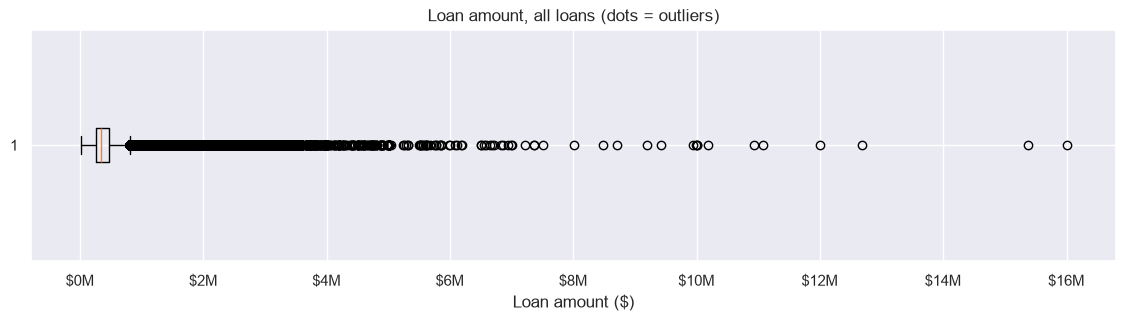

IQR rule: outliers are below $-75,000 or above $805,000
Outliers: 79,368 loans (3.25%)
Over $   1,000,000:   42,499 loans (1.741%)
Over $   2,000,000:    3,852 loans (0.158%)
Over $   5,000,000:       81 loans (0.003%)
Over $  10,000,000:        9 loans (0.000%)


In [14]:
# Outliers in loan_amount: box plot of ALL loans + counts
s = df["loan_amount"]

fig, ax = plt.subplots(figsize=(14, 3))
ax.boxplot(s, vert=False, whis=1.5)
ax.set_xlabel("Loan amount ($)")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"${x/1e6:,.0f}M"))
ax.set_title("Loan amount, all loans (dots = outliers)")
plt.show()

# Outlier rule used by the box plot (IQR rule)
q1, q3 = s.quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
n_out = ((s < low) | (s > high)).sum()
print(f"IQR rule: outliers are below ${low:,.0f} or above ${high:,.0f}")
print(f"Outliers: {n_out:,} loans ({n_out / len(s) * 100:.2f}%)")

# How many loans are above different sizes
for t in [1_000_000, 2_000_000, 5_000_000, 10_000_000]:
    n = (s > t).sum()
    print(f"Over ${t:>12,.0f}: {n:>8,} loans ({n / len(s) * 100:.3f}%)")

# interest rate

In [15]:
# interest_rate: remove missing (incl. 0% loans) and rates under 1%, then show the summary
before = len(df)
df = df.dropna(subset=["interest_rate"])
print(f"Removed {before - len(df):,} loans with missing interest rate")

before = len(df)
df = df[df["interest_rate"] >= 1]
print(f"Removed {before - len(df):,} loans with interest rate under 1%")
print(f"Rows left: {len(df):,}")

Removed 747 loans with missing interest rate
Removed 5 loans with interest rate under 1%
Rows left: 2,440,825


In [16]:
# Summary of the quantitative columns: total rows, missing, min, quartiles, max, mean
summary = df[num_cols].describe().T
summary["rows"] = len(df)                                      # total rows, same for every column
summary["missing"] = df[num_cols].isna().sum()
summary["missing_pct"] = (summary["missing"] / len(df) * 100).round(2)

summary = summary[["rows", "missing", "missing_pct", "min", "25%", "50%", "75%", "max", "mean"]]
pd.set_option("display.float_format", "{:,.2f}".format)
summary

,rows,missing,missing_pct,min,25%,50%,75%,max,mean
loan_amount,2440825,0,0.00,"5,000.00","255,000.00","345,000.00","475,000.00","16,005,000.00","389,106.81"
loan_to_value_ratio,2440825,71315,2.92,1.00,80.00,90.00,96.50,403.42,85.16
interest_rate,2440825,0,0.00,1.00,6.12,6.50,6.88,20.00,6.50
rate_spread,2440825,15208,0.62,-508.00,-0.22,0.16,0.57,"2,402.00",0.17
discount_points,2440825,1023725,41.94,0.00,"1,336.44","3,026.55","5,732.29","522,500.00","4,288.66"
lender_credits,2440825,1583190,64.86,0.01,79.00,515.22,"2,000.00","368,419.44","1,682.25"
loan_term,2440825,0,0.00,360.00,360.00,360.00,360.00,360.00,360.00
property_value,2440825,5725,0.23,"5,000.00","295,000.00","395,000.00","565,000.00","2,147,483,647.00","475,578.31"
income,2440825,17945,0.74,1.00,80.00,114.00,167.00,"476,447.00",154.49
tract_to_msa_income_percentage,2440825,0,0.00,0.00,83.00,104.00,129.00,412.09,108.81


# rate_spread

Missing rate_spread: 15,208


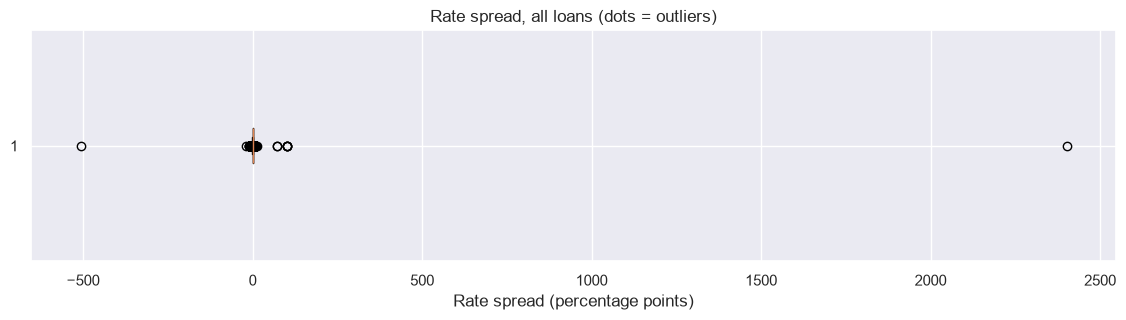

IQR rule: outliers are below -1.41 or above 1.75
Outliers: 102,898 loans (4.24%)
Spread under  -3:  1,748 loans
Spread under  -5:    355 loans
Spread under -10:      2 loans
Spread over    5:    780 loans
Spread over   10:      8 loans
Spread over   20:      7 loans


In [17]:
# rate_spread: missing count, box plot of ALL loans, and outlier counts
print(f"Missing rate_spread: {df['rate_spread'].isna().sum():,}")
s = df["rate_spread"].dropna()

fig, ax = plt.subplots(figsize=(14, 3))
ax.boxplot(s, orientation="horizontal", whis=1.5)
ax.set_xlabel("Rate spread (percentage points)")
ax.set_title("Rate spread, all loans (dots = outliers)")
plt.show()

q1, q3 = s.quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
n_out = ((s < low) | (s > high)).sum()
print(f"IQR rule: outliers are below {low:.2f} or above {high:.2f}")
print(f"Outliers: {n_out:,} loans ({n_out / len(s) * 100:.2f}%)")

for t in [-3, -5, -10]:
    print(f"Spread under {t:>3}: {(s < t).sum():>6,} loans")
for t in [5, 10, 20]:
    print(f"Spread over  {t:>3}: {(s > t).sum():>6,} loans")

Removed 15,208 loans with missing rate spread
Removed 14 loans with extreme rate spread
Rows left: 2,425,603


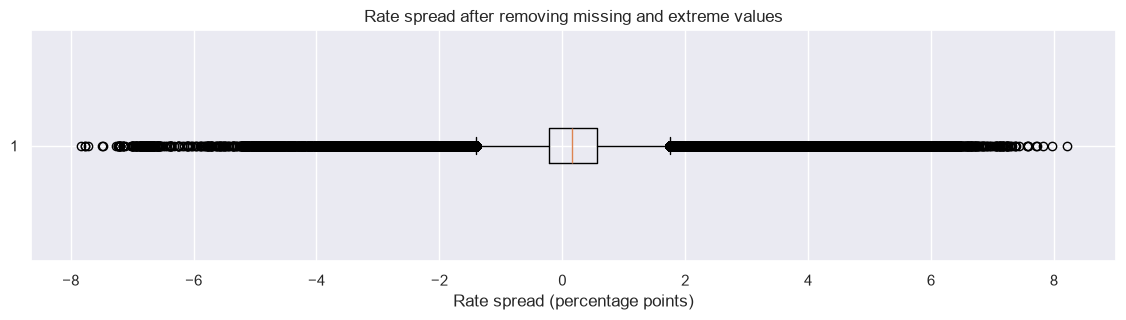

New min: -7.84   New max: 8.21


In [18]:
# rate_spread: remove missing values and the extreme values, then re-plot
before = len(df)
df = df.dropna(subset=["rate_spread"])
print(f"Removed {before - len(df):,} loans with missing rate spread")

before = len(df)
df = df[(df["rate_spread"] > -10) & (df["rate_spread"] < 10)]     # removes the -508 and 2,402
print(f"Removed {before - len(df):,} loans with extreme rate spread")
print(f"Rows left: {len(df):,}")

# Re-plot with the extremes gone
s = df["rate_spread"]
fig, ax = plt.subplots(figsize=(14, 3))
ax.boxplot(s, orientation="horizontal", whis=1.5)
ax.set_xlabel("Rate spread (percentage points)")
ax.set_title("Rate spread after removing missing and extreme values")
plt.show()

print(f"New min: {s.min():.2f}   New max: {s.max():.2f}")

# discount_points

In [19]:
# Original values of discount_points, for the loans still in df
raw = filtered_data.loc[df.index, "discount_points"]

print("Blank:  ", raw.isna().sum())
print("NA:     ", (raw == "NA").sum())
print("Exempt: ", (raw == "Exempt").sum())
print("Number: ", pd.to_numeric(raw, errors="coerce").notna().sum())

Blank:   972228
NA:      44740
Exempt:  11
Number:  1408624


In [20]:
# discount_points: blank -> 0 (no points paid), then remove NA / Exempt loans
raw = filtered_data.loc[df.index, "discount_points"]     # original values for the rows still in df
df.loc[raw.isna(), "discount_points"] = 0                 # blank = no points paid -> 0
print(f"Set to 0 (blank): {raw.isna().sum():,}")

before = len(df)
df = df.dropna(subset=["discount_points"])                # what's still empty is NA / Exempt -> remove
print(f"Removed (NA / Exempt): {before - len(df):,}")
print(f"Rows left: {len(df):,}")

Set to 0 (blank): 972,228
Removed (NA / Exempt): 44,751
Rows left: 2,380,852


# lender_credits(might need to check if we should get rid of the outlier here)

In [21]:
# lender_credits: check the original values, then blank -> 0 and remove NA / Exempt
raw = filtered_data.loc[df.index, "lender_credits"]       # original values for the rows still in df
print("Blank:  ", raw.isna().sum())
print("NA:     ", (raw == "NA").sum())
print("Exempt: ", (raw == "Exempt").sum())
print("Number: ", pd.to_numeric(raw, errors="coerce").notna().sum())

df.loc[raw.isna(), "lender_credits"] = 0                   # blank = no credits given -> 0
print(f"\nSet to 0 (blank): {raw.isna().sum():,}")

before = len(df)
df = df.dropna(subset=["lender_credits"])                  # what's still empty is NA / Exempt -> remove
print(f"Removed (NA / Exempt): {before - len(df):,}")
print(f"Rows left: {len(df):,}")

Blank:   1511325
NA:      35549
Exempt:  0
Number:  833978

Set to 0 (blank): 1,511,325
Removed (NA / Exempt): 35,549
Rows left: 2,345,303


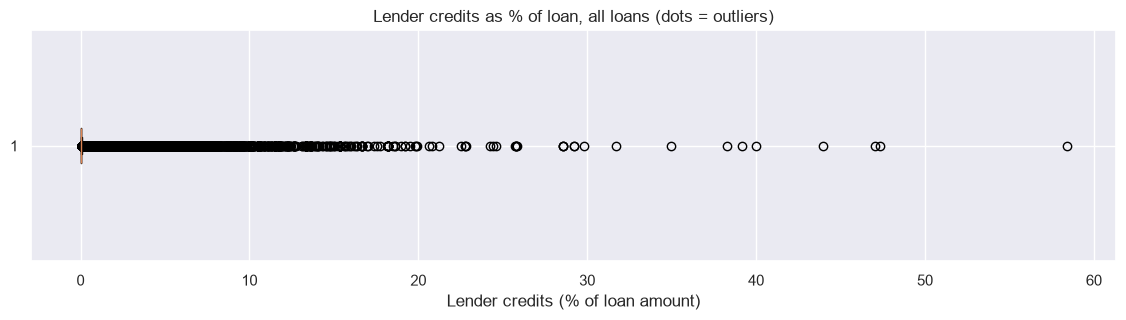

Loans with no credits: 1,511,325 (64.4%)
Median of loans WITH credits: 0.14%
Credits over  3% of loan:  8,471 loans (0.361%)
Credits over  5% of loan:  2,087 loans (0.089%)
Credits over 10% of loan:    278 loans (0.012%)
Credits over 20% of loan:     30 loans (0.001%)


In [22]:
# lender_credits as % of loan amount: box plot + counts
credits_pct = df["lender_credits"] / df["loan_amount"] * 100

fig, ax = plt.subplots(figsize=(14, 3))
ax.boxplot(credits_pct, orientation="horizontal", whis=1.5)
ax.set_xlabel("Lender credits (% of loan amount)")
ax.set_title("Lender credits as % of loan, all loans (dots = outliers)")
plt.show()

print(f"Loans with no credits: {(credits_pct == 0).sum():,} ({(credits_pct == 0).mean() * 100:.1f}%)")
print(f"Median of loans WITH credits: {credits_pct[credits_pct > 0].median():.2f}%")
for t in [3, 5, 10, 20]:
    n = (credits_pct > t).sum()
    print(f"Credits over {t:>2}% of loan: {n:>6,} loans ({n / len(df) * 100:.3f}%)")

# get rid of loan_term since they are all the same

In [23]:
# loan_term is 360 for every loan (because of our filter), so it adds nothing -> drop it
df = df.drop(columns=["loan_term"])
num_cols = [c for c in num_cols if c != "loan_term"]     # also remove it from the list of number columns

print(f"Columns left: {df.shape[1]}")

Columns left: 25


# property_value

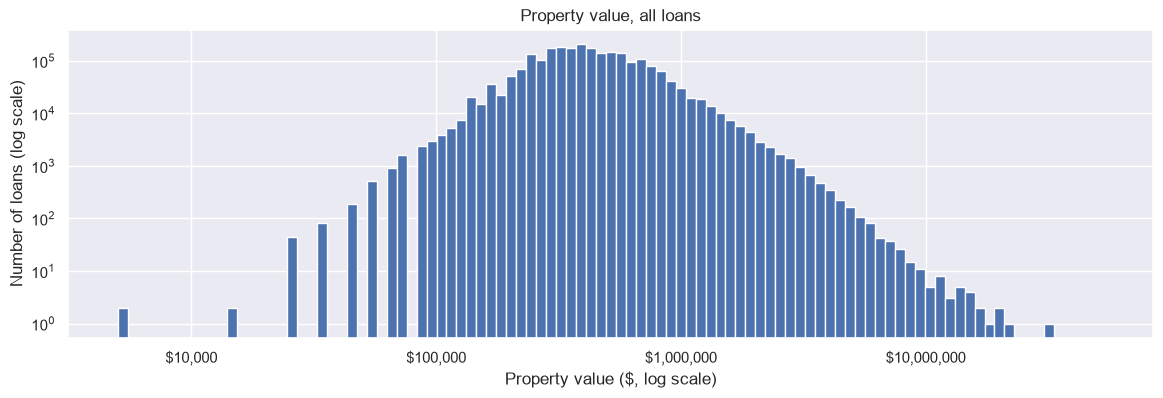

Median: $395,000   Min: $5,000   Max: $53,505,000
Under $    10,000:      2 loans
Under $    25,000:      4 loans
Under $    50,000:    319 loans
Over  $ 5,000,000:    398 loans
Over  $10,000,000:     33 loans
Over  $20,000,000:      4 loans


In [24]:
# property_value: histogram (log scale) + counts at both ends
s = df["property_value"].dropna()

bins = np.logspace(np.log10(s.min()), np.log10(s.max()), 100)   # 100 bars, evenly spaced on a log scale
fig, ax = plt.subplots(figsize=(14, 4))
ax.hist(s, bins=bins)
ax.set_xscale("log")
ax.set_yscale("log")                                             # so bars with only a few homes are visible
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"${x:,.0f}"))
ax.set_xlabel("Property value ($, log scale)")
ax.set_ylabel("Number of loans (log scale)")
ax.set_title("Property value, all loans")
plt.show()

print(f"Median: ${s.median():,.0f}   Min: ${s.min():,.0f}   Max: ${s.max():,.0f}")
for t in [10_000, 25_000, 50_000]:
    print(f"Under ${t:>10,}: {(s < t).sum():>6,} loans")
for t in [5_000_000, 10_000_000, 20_000_000]:
    print(f"Over  ${t:>10,}: {(s > t).sum():>6,} loans")

In [25]:
# property_value: remove missing values and unrealistically cheap homes (keep the high end)
min_value = 25_000            # change this if the team prefers a different cut-off

before = len(df)
df = df.dropna(subset=["property_value"])
print(f"Removed (missing): {before - len(df):,}")

before = len(df)
df = df[df["property_value"] >= min_value]
print(f"Removed (under ${min_value:,}): {before - len(df):,}")
print(f"Rows left: {len(df):,}   New min: ${df['property_value'].min():,.0f}")

Removed (missing): 5,525
Removed (under $25,000): 4
Rows left: 2,339,774   New min: $25,000


# income

Missing income: 16,255


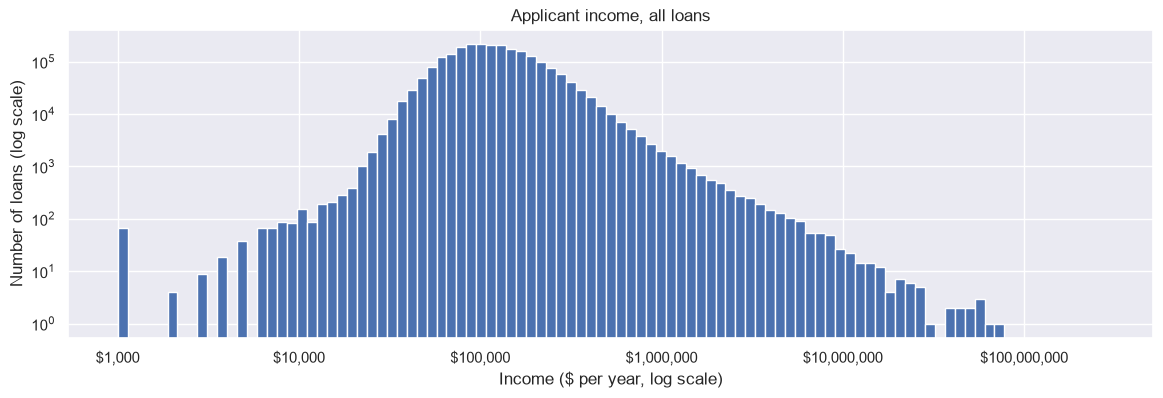

Median: $114,000   Min: $1,000   Max: $276,000,000
Under $    10,000:    444 loans
Under $    15,000:    882 loans
Under $    20,000:  1,550 loans
Over  $ 1,000,000:  7,951 loans
Over  $ 2,000,000:  2,236 loans
Over  $ 5,000,000:    438 loans
Over  $10,000,000:    100 loans


In [26]:
# income: missing count, histogram (log scale) + counts at both ends
print(f"Missing income: {df['income'].isna().sum():,}")
s = df["income"].dropna()

bins = np.logspace(np.log10(s.min()), np.log10(s.max()), 100)
fig, ax = plt.subplots(figsize=(14, 4))
ax.hist(s, bins=bins)
ax.set_xscale("log")
ax.set_yscale("log")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"${x * 1000:,.0f}"))   # show real dollars
ax.set_xlabel("Income ($ per year, log scale)")
ax.set_ylabel("Number of loans (log scale)")
ax.set_title("Applicant income, all loans")
plt.show()

print(f"Median: ${s.median() * 1000:,.0f}   Min: ${s.min() * 1000:,.0f}   Max: ${s.max() * 1000:,.0f}")
for t in [10, 15, 20]:
    print(f"Under ${t * 1000:>10,}: {(s < t).sum():>6,} loans")
for t in [1_000, 2_000, 5_000, 10_000]:
    print(f"Over  ${t * 1000:>10,}: {(s > t).sum():>6,} loans")

In [27]:
# income (in $ thousands): remove missing and under $10k; keep the high end
before = len(df)
df = df.dropna(subset=["income"])
print(f"Removed (missing income): {before - len(df):,}")

before = len(df)
df = df[(df["income"] >= 10) & (df["income"] <= 5000)]                 
print(f"Removed (outside $10k–$5M): {before - len(df):,}")

print(f"Rows left: {len(df):,}   New min: ${df['income'].min() * 1000:,.0f}")

Removed (missing income): 16,255
Removed (outside $10k–$5M): 882
Rows left: 2,322,637   New min: $10,000


In [28]:
# Summary of the quantitative columns: total rows, missing, min, quartiles, max, mean
summary = df[num_cols].describe().T
summary["rows"] = len(df)                                      # total rows, same for every column
summary["missing"] = df[num_cols].isna().sum()
summary["missing_pct"] = (summary["missing"] / len(df) * 100).round(2)

summary = summary[["rows", "missing", "missing_pct", "min", "25%", "50%", "75%", "max", "mean"]]
pd.set_option("display.float_format", "{:,.2f}".format)
summary

,rows,missing,missing_pct,min,25%,50%,75%,max,mean
loan_amount,2322637,0,0.00,"5,000.00","255,000.00","345,000.00","475,000.00","11,075,000.00","388,614.53"
loan_to_value_ratio,2322637,67195,2.89,1.00,80.00,90.00,96.50,403.42,85.20
interest_rate,2322637,0,0.00,1.00,6.12,6.50,6.88,20.00,6.49
rate_spread,2322637,0,0.00,-7.84,-0.23,0.16,0.56,8.21,0.16
discount_points,2322637,0,0.00,0.00,0.00,758.89,"3,653.85","235,660.00","2,518.26"
lender_credits,2322637,0,0.00,0.00,0.00,0.00,118.00,"99,949.80",589.50
property_value,2322637,0,0.00,"25,000.00","295,000.00","395,000.00","565,000.00","53,505,000.00","473,577.19"
income,2322637,0,0.00,10.00,80.00,114.00,167.00,"5,000.00",144.82
tract_to_msa_income_percentage,2322637,0,0.00,0.00,83.00,104.00,129.00,412.09,108.78


# tract_to_msa_income_percentage

In [29]:
# tract_to_msa_income_percentage: 0 means no data for the tract -> mark as missing (keep the loan)
n = (df["tract_to_msa_income_percentage"] < 10).sum()
df.loc[df["tract_to_msa_income_percentage"] < 10, "tract_to_msa_income_percentage"] = np.nan
print(f"Set to missing: {n:,} loans")

Set to missing: 14,399 loans


# loan to value ratio calculation

In [30]:
# Calculated LTV (after loan_amount and property_value are cleaned)
df["loan_to_value_ratio_calculated"] = df["loan_amount"] / df["property_value"] * 100

# Add it to the list of number columns
if "loan_to_value_ratio_calculated" not in num_cols:
    num_cols.append("loan_to_value_ratio_calculated")

# Summary of the quantitative columns: total rows, missing, min, quartiles, max, mean
summary = df[num_cols].describe().T
summary["rows"] = len(df)
summary["missing"] = df[num_cols].isna().sum()
summary["missing_pct"] = (summary["missing"] / len(df) * 100).round(2)

summary = summary[["rows", "missing", "missing_pct", "min", "25%", "50%", "75%", "max", "mean"]]
pd.set_option("display.float_format", "{:,.2f}".format)
summary

,rows,missing,missing_pct,min,25%,50%,75%,max,mean
loan_amount,2322637,0,0.00,"5,000.00","255,000.00","345,000.00","475,000.00","11,075,000.00","388,614.53"
loan_to_value_ratio,2322637,67195,2.89,1.00,80.00,90.00,96.50,403.42,85.20
interest_rate,2322637,0,0.00,1.00,6.12,6.50,6.88,20.00,6.49
rate_spread,2322637,0,0.00,-7.84,-0.23,0.16,0.56,8.21,0.16
discount_points,2322637,0,0.00,0.00,0.00,758.89,"3,653.85","235,660.00","2,518.26"
lender_credits,2322637,0,0.00,0.00,0.00,0.00,118.00,"99,949.80",589.50
property_value,2322637,0,0.00,"25,000.00","295,000.00","395,000.00","565,000.00","53,505,000.00","473,577.19"
income,2322637,0,0.00,10.00,80.00,114.00,167.00,"5,000.00",144.82
tract_to_msa_income_percentage,2322637,14399,0.62,12.00,84.00,104.83,129.00,412.09,109.45
loan_to_value_ratio_calculated,2322637,0,0.00,0.79,79.38,91.06,97.10,926.78,85.36


In [31]:
# Drop the original reported LTV and keep only our calculated one
df = df.drop(columns=["loan_to_value_ratio"])
num_cols = [c for c in num_cols if c != "loan_to_value_ratio"]

print(f"Columns left: {df.shape[1]}")

Columns left: 25


In [32]:
# Summary of the quantitative columns: total rows, missing, min, quartiles, max, mean
summary = df[num_cols].describe().T
summary["rows"] = len(df)
summary["missing"] = df[num_cols].isna().sum()
summary["missing_pct"] = (summary["missing"] / len(df) * 100).round(2)

summary = summary[["rows", "missing", "missing_pct", "min", "25%", "50%", "75%", "max", "mean"]]
pd.set_option("display.float_format", "{:,.2f}".format)
summary

,rows,missing,missing_pct,min,25%,50%,75%,max,mean
loan_amount,2322637,0,0.00,"5,000.00","255,000.00","345,000.00","475,000.00","11,075,000.00","388,614.53"
interest_rate,2322637,0,0.00,1.00,6.12,6.50,6.88,20.00,6.49
rate_spread,2322637,0,0.00,-7.84,-0.23,0.16,0.56,8.21,0.16
discount_points,2322637,0,0.00,0.00,0.00,758.89,"3,653.85","235,660.00","2,518.26"
lender_credits,2322637,0,0.00,0.00,0.00,0.00,118.00,"99,949.80",589.50
property_value,2322637,0,0.00,"25,000.00","295,000.00","395,000.00","565,000.00","53,505,000.00","473,577.19"
income,2322637,0,0.00,10.00,80.00,114.00,167.00,"5,000.00",144.82
tract_to_msa_income_percentage,2322637,14399,0.62,12.00,84.00,104.83,129.00,412.09,109.45
loan_to_value_ratio_calculated,2322637,0,0.00,0.79,79.38,91.06,97.10,926.78,85.36


In [33]:
# Keep LTV between 5 and 125
before = len(df)
df = df[df["loan_to_value_ratio_calculated"].between(5, 125)]
print(f"Removed {before - len(df):,} loans  |  {len(df):,} left")

Removed 541 loans  |  2,322,096 left


In [34]:
# Remove unrealistic points/credits (over 10% of the loan) and the 15 "Exempt" AUS loans
before = len(df)
df = df[(df["discount_points"] <= 0.10 * df["loan_amount"]) &
        (df["lender_credits"] <= 0.10 * df["loan_amount"])]
df = df[df["aus"] != "Exempt"]
print(f"Removed {before - len(df):,} loans  |  {len(df):,} left")

Removed 551 loans  |  2,321,545 left


# Cleaned summary table

In [35]:
# Summary of the quantitative columns: total rows, missing, min, quartiles, max, mean
summary = df[num_cols].describe().T
summary["rows"] = len(df)                                      # total rows, same for every column
summary["missing"] = df[num_cols].isna().sum()
summary["missing_pct"] = (summary["missing"] / len(df) * 100).round(2)

summary = summary[["rows", "missing", "missing_pct", "min", "25%", "50%", "75%", "max", "mean"]]
pd.set_option("display.float_format", "{:,.2f}".format)
summary

,rows,missing,missing_pct,min,25%,50%,75%,max,mean
loan_amount,2321545,0,0.00,"15,000.00","255,000.00","345,000.00","475,000.00","10,005,000.00","388,668.38"
interest_rate,2321545,0,0.00,1.00,6.12,6.50,6.88,20.00,6.49
rate_spread,2321545,0,0.00,-7.84,-0.23,0.16,0.56,8.21,0.16
discount_points,2321545,0,0.00,0.00,0.00,758.15,"3,652.31","161,784.02","2,516.00"
lender_credits,2321545,0,0.00,0.00,0.00,0.00,117.50,"99,949.80",587.77
property_value,2321545,0,0.00,"25,000.00","295,000.00","395,000.00","565,000.00","16,805,000.00","473,633.92"
income,2321545,0,0.00,10.00,80.00,114.00,167.00,"5,000.00",144.83
tract_to_msa_income_percentage,2321545,14395,0.62,12.00,84.00,104.83,129.00,412.09,109.46
loan_to_value_ratio_calculated,2321545,0,0.00,5.08,79.38,91.06,97.10,124.82,85.36


# categorize the ethnicity group

In [36]:
# Create the race/ethnicity group (Hispanic first, then non-Hispanic races)
eth = df["derived_ethnicity"].astype(str)
race = df["derived_race"].astype(str)
not_hisp = eth == "Not Hispanic or Latino"
unknown = eth.isin(["Ethnicity Not Available", "Free Form Text Only"]) | \
          race.isin(["Race Not Available", "Free Form Text Only"])

df["race_group"] = np.select(
    [eth == "Hispanic or Latino",
     not_hisp & (race == "White"),
     not_hisp & (race == "Black or African American"),
     not_hisp & (race == "Asian"),
     unknown],
    ["Hispanic", "White", "Black", "Asian", "Not reported"],
    default="Other")

df["race_group"] = pd.Categorical(df["race_group"],
                                  categories=["White", "Hispanic", "Black", "Asian", "Other", "Not reported"])

counts = df["race_group"].value_counts()
print(counts, "\nTotal:", counts.sum(), " | rows in df:", len(df))

race_group
White           1125961
Not reported     348859
Hispanic         331343
Black            253200
Asian            139031
Other            123151
Name: count, dtype: int64 
Total: 2321545  | rows in df: 2321545


In [37]:
# # saved the clean data
# df.to_csv("hmda_clean.csv", index=False)
# print(f"Saved {len(df):,} rows x {df.shape[1]} columns")

In [38]:
# Load the cleaned data and set the categorical columns again
df = pd.read_csv("hmda_clean.csv",
                 dtype={"activity_year": str, "lei": str, "msa_md": str, "county_code": str,
                        "state_code": str, "conforming_loan_limit": str})

cat_cols = ["activity_year", "lei", "msa_md", "state_code", "county_code",
            "conforming_loan_limit", "derived_ethnicity", "derived_race", "derived_sex",
            "preapproval", "loan_type", "loan_purpose", "aus",
            "applicant_age", "debt_to_income_ratio"]
cat_cols = [c for c in cat_cols if c in df.columns]      # skip any column you dropped

df[cat_cols] = df[cat_cols].astype("category")
print(f"Loaded {len(df):,} rows x {df.shape[1]} columns   |   categorical columns: {len(cat_cols)}")
df.head()

Loaded 2,321,545 rows x 26 columns   |   categorical columns: 15


,activity_year,lei,msa_md,state_code,county_code,conforming_loan_limit,derived_ethnicity,derived_race,derived_sex,preapproval,loan_type,loan_purpose,loan_amount,interest_rate,rate_spread,discount_points,lender_credits,intro_rate_period,property_value,applicant_age,income,debt_to_income_ratio,aus,tract_to_msa_income_percentage,loan_to_value_ratio_calculated,race_group
0,2023,549300VZVN841I2ILS84,38860,ME,23023,C,Hispanic or Latino,Joint,Male,Not requested,VA,Purchase,"405,000.00",6.75,0.10,"5,694.30",10.95,NaN,"405,000.00",25-34,151.00,36%-<43%,Desktop Underwriter,102.88,100.00,Hispanic
1,2023,549300VZVN841I2ILS84,38860,ME,23031,C,Not Hispanic or Latino,White,Male,Not requested,Conventional,Purchase,"565,000.00",6.95,0.38,0.00,4.25,NaN,"705,000.00",25-34,236.00,20%-<30%,Loan Product Advisor,150.67,80.14,White
2,2023,549300VZVN841I2ILS84,99999,ME,23009,C,Not Hispanic or Latino,White,Female,Not requested,Conventional,Purchase,"225,000.00",6.88,0.48,"2,690.40",45.00,NaN,"245,000.00",45-54,87.00,36%-<43%,Desktop Underwriter,83.37,91.84,White
3,2023,549300VZVN841I2ILS84,99999,ME,23015,C,Not Hispanic or Latino,White,Male,Not requested,Conventional,Purchase,"365,000.00",6.95,0.32,650.48,0.00,NaN,"525,000.00",55-64,393.00,<20%,Desktop Underwriter,105.24,69.52,White
4,2023,549300VZVN841I2ILS84,38860,ME,23031,C,Not Hispanic or Latino,White,Male,Not requested,Conventional,Purchase,"655,000.00",7.45,1.11,0.00,0.00,NaN,"675,000.00",35-44,240.00,36%-<43%,Desktop Underwriter,83.92,97.04,White


# check the number of application in each years

In [39]:
# Compare loans per year: full cleaned data vs 10k sample
year_check = pd.DataFrame({
    "sample_count": df["activity_year"].value_counts(),
    "sample_pct":   df["activity_year"].value_counts(normalize=True) * 100,
}).sort_index()
year_check.round(2)

,sample_count,sample_pct
activity_year,,
2023,777847,33.51
2024,783552,33.75
2025,760146,32.74


In [40]:
# Number and share of loans by gender
counts = df["derived_sex"].value_counts(dropna=False)
pct = (df["derived_sex"].value_counts(normalize=True, dropna=False) * 100).round(1)
pd.DataFrame({"loans": counts, "pct": pct})

,loans,pct
derived_sex,,
Joint,864932,37.30
Male,783938,33.80
Female,556454,24.00
Sex Not Available,116221,5.00


In [41]:
# Race/ethnicity groups in the sample: count and %
group_check = pd.DataFrame({
    "count": df["race_group"].value_counts(),
    "pct":   (df["race_group"].value_counts(normalize=True) * 100).round(1),
})
print("Total:", group_check["count"].sum())
group_check

Total: 2321545


,count,pct
race_group,,
White,1125961,48.50
Not reported,348859,15.00
Hispanic,331343,14.30
Black,253200,10.90
Asian,139031,6.00
Other,123151,5.30


# Mutiple Linear Regression

# run model

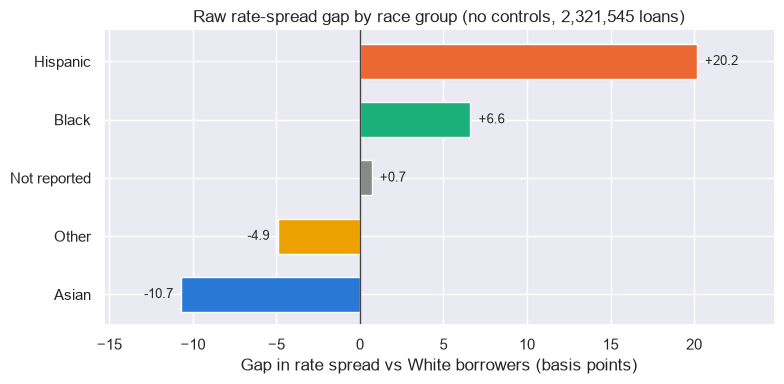

In [42]:
# Model 1 on the full data (saved as m1): raw gap, race group only
m1 = smf.ols('rate_spread ~ C(race_group, Treatment(reference="White"))', data=df).fit()

# Raw gap for each group vs White, in basis points
group_colors = {"Hispanic": "#eb6834", "Black": "#1baf7a", "Asian": "#2a78d6",
                "Other": "#eda100", "Not reported": "#8a8a85"}

gaps = m1.params.loc[lambda s: s.index.str.startswith("C(race_group")]
gaps.index = gaps.index.str.extract(r"T\.(.+)\]")[0]
gaps = (gaps * 100).sort_values()

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(gaps.index, gaps, color=[group_colors[g] for g in gaps.index], height=0.6)
ax.axvline(0, color="#444", linewidth=1)
for i, v in enumerate(gaps):
    ax.text(v + (0.5 if v >= 0 else -0.5), i, f"{v:+.1f}",
            va="center", ha="left" if v >= 0 else "right", fontsize=9)
ax.set_xlabel("Gap in rate spread vs White borrowers (basis points)")
ax.set_title(f"Raw rate-spread gap by race group (no controls, {int(m1.nobs):,} loans)")
ax.spines[["top", "right"]].set_visible(False)
ax.margins(x=0.15)
plt.tight_layout()
plt.show()

## The above graph shows if we only look at race group without anything else this is how much difference amount the groups compare with baseline(white)

In [43]:
print(m1.summary())

                            OLS Regression Results                            
Dep. Variable:            rate_spread   R-squared:                       0.012
Model:                            OLS   Adj. R-squared:                  0.012
Method:                 Least Squares   F-statistic:                     5461.
Date:                Mon, 09 Nov 2026   Prob (F-statistic):               0.00
Time:                        10:49:37   Log-Likelihood:            -2.5718e+06
No. Observations:             2321545   AIC:                         5.144e+06
Df Residuals:                 2321539   BIC:                         5.144e+06
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                                                  coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------

In [44]:
# # Loans in the model (m1) by race group
# used = df.loc[m1.model.data.row_labels]          # the exact rows the model used

# table = used.groupby("race_group", observed=True)["rate_spread"].agg(loans="count", avg_rate_spread="mean")
# table["share_%"] = (table["loans"] / table["loans"].sum() * 100).round(1)
# table["gap_vs_White_bps"] = ((table["avg_rate_spread"] - table.loc["White", "avg_rate_spread"]) * 100).round(1)
# table["avg_rate_spread"] = table["avg_rate_spread"].round(3)

# print(f"Total loans in the model: {int(m1.nobs):,}")
# table

In [45]:
BASE = ('C(race_group, Treatment(reference="White")) '
        "+ np.log(income) + np.log(loan_amount) + loan_to_value_ratio_calculated "
        "+ debt_to_income_ratio + loan_type + C(conforming_loan_limit) "
        "+ aus + preapproval + tract_to_msa_income_percentage "
        "+ state_code + C(activity_year)")

leaky = smf.ols(f"rate_spread ~ interest_rate + {BASE}", data=df).fit()
clean = smf.ols(f"rate_spread ~ {BASE}", data=df).fit()

print(f"Leaky R² = {leaky.rsquared:.3f}   Clean R² = {clean.rsquared:.3f}   N = {int(clean.nobs):,}")
print("interest_rate is part of how rate_spread is calculated, so including it inflates R². We leave it out.")
print(clean.summary())

Leaky R² = 0.753   Clean R² = 0.210   N = 2,304,996
interest_rate is part of how rate_spread is calculated, so including it inflates R². We leave it out.
                            OLS Regression Results                            
Dep. Variable:            rate_spread   R-squared:                       0.210
Model:                            OLS   Adj. R-squared:                  0.210
Method:                 Least Squares   F-statistic:                 1.462e+04
Date:                Mon, 09 Nov 2026   Prob (F-statistic):               0.00
Time:                        10:49:53   Log-Likelihood:            -2.2934e+06
No. Observations:             2304996   AIC:                         4.587e+06
Df Residuals:                 2304953   BIC:                         4.587e+06
Df Model:                          42                                         
Covariance Type:            nonrobust                                         
                                                        

In [46]:
print(leaky.summary())

                            OLS Regression Results                            
Dep. Variable:            rate_spread   R-squared:                       0.753
Model:                            OLS   Adj. R-squared:                  0.753
Method:                 Least Squares   F-statistic:                 1.631e+05
Date:                Mon, 09 Nov 2026   Prob (F-statistic):               0.00
Time:                        10:49:53   Log-Likelihood:            -9.5538e+05
No. Observations:             2304996   AIC:                         1.911e+06
Df Residuals:                 2304952   BIC:                         1.911e+06
Df Model:                          43                                         
Covariance Type:            nonrobust                                         
                                                                  coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------

# ------------------------------------------------------------------

In [47]:
# Each category's FIRST level is the baseline; every coefficient is a difference from it
def set_baseline(col, baseline, order=None):
    levels = order if order is not None else [baseline] + sorted(set(df[col].dropna()) - {baseline})
    df[col] = pd.Categorical(df[col], categories=levels)

set_baseline("race_group", "White", ["White", "Hispanic", "Black", "Asian", "Other", "Not reported"])
set_baseline("derived_sex", "Male")
set_baseline("applicant_age", "35-44", ["35-44", "<25", "25-34", "45-54", "55-64", "65-74", ">74"])
set_baseline("activity_year", "2023")
set_baseline("debt_to_income_ratio", "<20%",
             ["<20%", "20%-<30%", "30%-<36%", "36%-<43%", "43%-<50%", "50%-60%", ">60%"])
set_baseline("loan_type", "Conventional")
set_baseline("conforming_loan_limit", "C")
set_baseline("aus", "Desktop Underwriter")
set_baseline("state_code", "FL")                 # largest state

# Financial and loan variables
df["log_income"] = np.log(df["income"].where(df["income"] > 0))     # logs because income and loan size are strongly skewed
df["log_loan"] = np.log(df["loan_amount"].where(df["loan_amount"] > 0))
df["ltv_band"] = pd.cut(df["loan_to_value_ratio_calculated"], [0, 80, 90, 95, 97, np.inf],
                        labels=["80% or less", "80-90%", "90-95%", "95-97%", "over 97%"])  # pricing jumps at these lines
df["points_pct"] = df["discount_points"] / df["loan_amount"] * 100      # points paid, % of the loan
df["credits_pct"] = df["lender_credits"] / df["loan_amount"] * 100
df["preapproval_req"] = (df["preapproval"] == "Requested").astype(int)

# Keep loans that have every model variable, so all models use exactly the same loans
model_cols = ["interest_rate", "rate_spread", "race_group", "derived_sex", "applicant_age", "activity_year",
              "log_income", "log_loan", "ltv_band", "debt_to_income_ratio", "loan_type",
              "conforming_loan_limit", "aus", "preapproval_req", "points_pct", "credits_pct", "state_code", "lei"]
before = len(df)
df = df.dropna(subset=model_cols).reset_index(drop=True)
for c in df.select_dtypes("category").columns:
    df[c] = df[c].cat.remove_unused_categories()

groups = pd.factorize(df["lei"])[0]              # lender of each loan, for clustered standard errors
n_lenders = df["lei"].nunique()
print(f"{before:,} -> {len(df):,} loans  |  {n_lenders:,} lenders")

2,321,545 -> 2,319,349 loans  |  1,677 lenders


In [48]:
from scipy import stats

def restriction(names, terms):
    """Matrix that sets each term in `terms` to 0, for an F-test."""
    R = np.zeros((len(terms), len(names)))
    for i, t in enumerate(terms):
        R[i, names.index(t)] = 1
    return R

def fit(formula, data, groups):
    """Fit OLS; return (classical results, results with standard errors clustered by lender)."""
    classical = smf.ols(formula, data=data).fit()
    clustered = classical.get_robustcov_results(cov_type="cluster", groups=groups)
    return classical, clustered

def summarize(name, classical, clustered, prev=None):
    """Keep the numbers we report, so the large model objects can be deleted."""
    names = classical.model.exog_names
    race = [n for n in names if n.startswith("race_group[")]
    ft = clustered.f_test(restriction(names, race))                 # joint F-test: all group gaps = 0
    out = {"model": name, "n": int(classical.nobs), "k": len(names), "names": names,
           "r2": classical.rsquared, "adj_r2": classical.rsquared_adj,
           "ssr": classical.ssr, "df_resid": classical.df_resid,
           "b":  pd.Series(np.asarray(clustered.params), index=names),
           "se": pd.Series(np.asarray(clustered.bse), index=names),
           "p":  pd.Series(np.asarray(clustered.pvalues), index=names),
           "se_classical": pd.Series(np.asarray(classical.bse), index=names),
           "p_classical":  pd.Series(np.asarray(classical.pvalues), index=names),
           "race_F": float(np.squeeze(ft.fvalue)), "race_F_p": float(np.squeeze(ft.pvalue)),
           "race_F_df": (int(ft.df_num), int(ft.df_denom)),
           "race_F_classical": float(np.squeeze(classical.f_test(restriction(names, race)).fvalue))}
    if prev is not None:   # partial F-test: do the variables this model adds improve the fit?
        q = out["k"] - prev["k"]
        F = ((prev["ssr"] - out["ssr"]) / q) / (out["ssr"] / out["df_resid"])
        added = [n for n in names if n not in prev["names"]]
        ftb = clustered.f_test(restriction(names, added))
        out.update(partial_F=F, partial_df=(q, int(out["df_resid"])), partial_p=stats.f.sf(F, q, out["df_resid"]),
                   partial_F_clustered=float(np.squeeze(ftb.fvalue)),
                   partial_p_clustered=float(np.squeeze(ftb.pvalue)))
    return out

In [49]:
# building the model by adding more indep variable each model
# If asked "isn't 22% low?": "Yes, and that's expected. HMDA has no credit score, 
# no rate-lock date and no negotiation details, and those drive much of the price. 
#Our goal isn't to predict each loan's price. It's to compare similar borrowers fairly, and R² doesn't need to be high for that."
X1 = "race_group + activity_year"
X2 = X1 + " + derived_sex + applicant_age"
X3 = X2 + " + log_income + log_loan + ltv_band + debt_to_income_ratio"
X4 = X3 + " + loan_type + conforming_loan_limit + aus + preapproval_req + points_pct + credits_pct"
X5 = X4 + " + state_code"
ladder = {"1. Groups + year": X1,
          "2. + sex, age": X2,
          "3. + income, loan size, LTV, DTI": X3,
          "4. + loan type, conforming, AUS, preapproval, points, credits": X4,
          "5. + state (main)": X5}

results, prev = [], None
for name, rhs in ladder.items():
    classical, clustered = fit(f"rate_spread ~ {rhs}", df, groups)
    prev = summarize(name, classical, clustered, prev)
    results.append(prev)
    if name.startswith("5"):
        main_classical, main_clustered = classical, clustered     # keep the main model
    else:
        del classical, clustered                                    # free memory
    print(f"done: {name}   R² = {prev['r2']:.3f}")
m = results[-1]

done: 1. Groups + year   R² = 0.015
done: 2. + sex, age   R² = 0.017
done: 3. + income, loan size, LTV, DTI   R² = 0.093
done: 4. + loan type, conforming, AUS, preapproval, points, credits   R² = 0.216
done: 5. + state (main)   R² = 0.224


In [50]:
names = main_classical.model.exog_names 
keep = [n for n in names if not n.startswith(("state_code", "race_group"))] 
pd.DataFrame({"coef": m["b"][keep], "std err": m["se"][keep], "p": m["p"][keep]}).round(4) 

,coef,std err,p
Intercept,3.43,0.20,0.00
activity_year[T.2024],-0.05,0.02,0.00
activity_year[T.2025],-0.12,0.02,0.00
derived_sex[T.Female],-0.04,0.01,0.00
derived_sex[T.Joint],-0.04,0.01,0.00
derived_sex[T.Sex Not Available],-0.03,0.02,0.20
applicant_age[T.<25],0.02,0.01,0.05
applicant_age[T.25-34],-0.03,0.00,0.00
applicant_age[T.45-54],0.03,0.00,0.00
applicant_age[T.55-64],0.01,0.01,0.22


In [51]:
# Results table: gap vs. comparable non-Hispanic White borrowers, in bps (clustered standard error)
labels = {"race_group[T.Hispanic]": "Hispanic", "race_group[T.Black]": "Black",
          "race_group[T.Asian]": "Asian", "race_group[T.Other]": "Other",
          "race_group[T.Not reported]": "Not reported", "derived_sex[T.Female]": "Women (vs. men)"}

def cell(r, term):
    if term not in r["b"].index:
        return ""
    b, se, p = r["b"][term] * 100, r["se"][term] * 100, r["p"][term]
    stars = "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else ""
    return f"{b:+.1f}{stars} ({se:.1f})"

table = pd.DataFrame({r["model"]: [cell(r, t) for t in labels] + [f"{r['adj_r2']:.3f}", f"{r['n']:,}"]
                      for r in results}, index=list(labels.values()) + ["Adjusted R²", "Loans"])
table   # *** p < 0.001, ** p < 0.01, * p < 0.05

,1. Groups + year,"2. + sex, age","3. + income, loan size, LTV, DTI","4. + loan type, conforming, AUS, preapproval, points, credits",5. + state (main)
Hispanic,+20.1*** (5.5),+19.1*** (5.4),+17.5*** (5.2),+10.6* (4.3),+12.8*** (3.8)
Black,+6.4 (3.3),+5.5 (3.4),+3.0 (2.2),+1.7 (1.6),+0.2 (1.9)
Asian,-10.9*** (1.8),-11.7*** (1.8),-5.9** (2.0),-9.6*** (1.8),-10.7*** (2.3)
Other,-4.9* (1.9),-5.1** (2.0),-5.7*** (1.5),-3.2* (1.3),-2.8** (1.1)
Not reported,+0.5 (1.1),+0.2 (1.5),+0.2 (1.2),+0.5 (1.1),+0.4 (1.1)
Women (vs. men),,+3.1** (1.1),+2.5* (1.1),-3.9*** (0.7),-4.2*** (0.7)
Adjusted R²,0.015,0.017,0.093,0.216,0.224
Loans,"2,319,349","2,319,349","2,319,349","2,319,349","2,319,349"


# graph below here is for the table above # Results table: gap vs. comparable non-Hispanic White borrowers, in bps (clustered standard error)

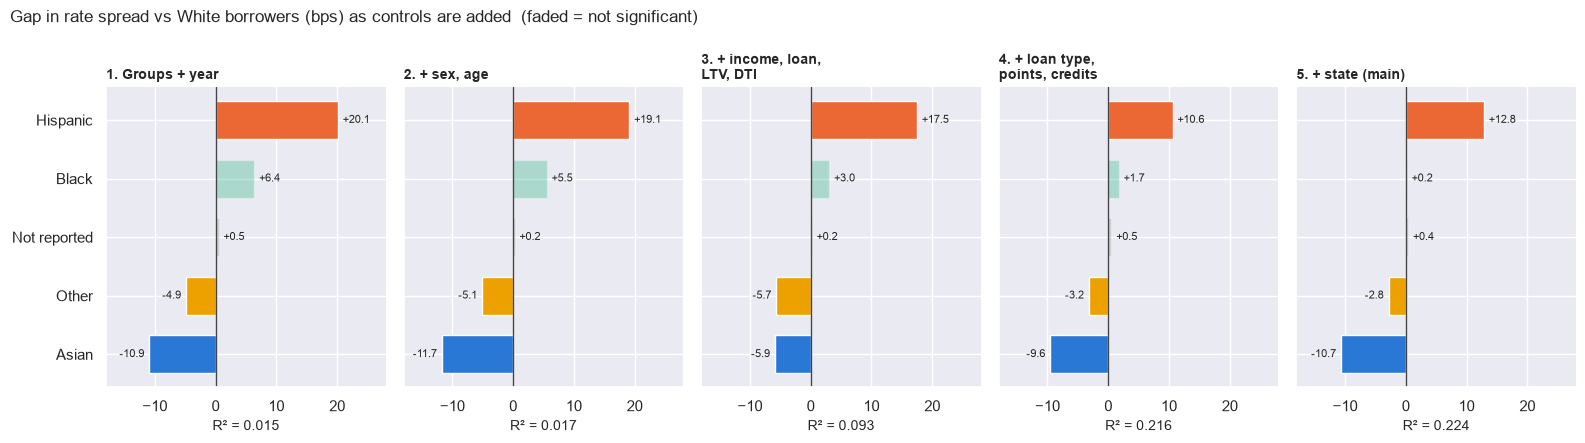

In [52]:
# Gap by group in each of the 5 models (one panel per model, R² underneath)
# Faded bar = not significant at 0.05
assert len(results) == 5, "results is empty: re-run the cell that fits the 5 models (X1 ... X5) first"
show_groups = ["Hispanic", "Black", "Not reported", "Other", "Asian"]
steps = ["1. Groups + year", "2. + sex, age", "3. + income, loan,\nLTV, DTI", "4. + loan type,\npoints, credits", "5. + state (main)"]

fig, axes = plt.subplots(1, 5, figsize=(16, 4.5), sharey=True, sharex=True)
for ax, step, r in zip(axes, steps, results):
    for i, g in enumerate(show_groups[::-1]):                 # Hispanic at the top
        term = f"race_group[T.{g}]"
        v, p = r["b"][term] * 100, r["p"][term]
        ax.barh(i, v, color=group_colors[g], height=0.65, alpha=1 if p < 0.05 else 0.3)
        ax.text(v + (0.8 if v >= 0 else -0.8), i, f"{v:+.1f}", va="center",
                ha="left" if v >= 0 else "right", fontsize=8)
    ax.axvline(0, color="#444", lw=1)
    ax.set_title(step, loc="left", fontsize=10, fontweight="bold")
    ax.set_xlabel(f"R² = {r['adj_r2']:.3f}", fontsize=10)
    ax.set_xlim(-18, 28)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_yticks(range(len(show_groups)))
axes[0].set_yticklabels(show_groups[::-1])
fig.suptitle("Gap in rate spread vs White borrowers (bps) as controls are added  (faded = not significant)",
             x=0.01, ha="left", fontsize=12)
plt.tight_layout()
plt.show()


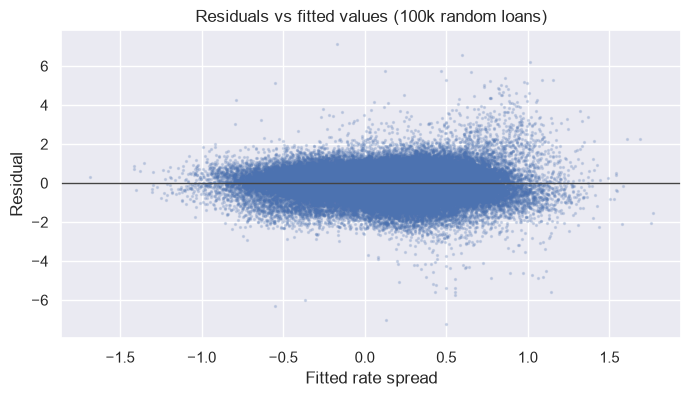

Breusch-Pagan: LM = 10,458.6, p = 0
RESET: F = 3.4, p = 0.0645


In [53]:
from statsmodels.stats.diagnostic import het_breuschpagan, linear_reset 
 
diag = df.sample(n=100_000, random_state=860).reset_index(drop=True) 
for c in diag.select_dtypes("category").columns: 
    diag[c] = diag[c].cat.remove_unused_categories() 
d = smf.ols(f"rate_spread ~ {X5}", data=diag).fit() 
 
# Residual plot 
fig, ax = plt.subplots(figsize=(8, 4)) 
ax.scatter(d.fittedvalues, d.resid, s=2, alpha=0.2) 
ax.axhline(0, color="#444", lw=1) 
ax.set_xlabel("Fitted rate spread"); ax.set_ylabel("Residual") 
ax.set_title("Residuals vs fitted values (100k random loans)") 
plt.show() 
 
# Breusch-Pagan test for heteroskedasticity 
lm, lm_p, f, f_p = het_breuschpagan(d.resid, d.model.exog) 
print(f"Breusch-Pagan: LM = {lm:,.1f}, p = {lm_p:.3g}") 
 
# RESET test for missing curvature 
reset = linear_reset(d, power=2, use_f=True) 
print(f"RESET: F = {reset.fvalue:,.1f}, p = {reset.pvalue:.3g}")

### for above graph: Diagnostics. This cell checks whether the model's assumptions hold. It runs on a random 100,000 loans, because 2.3 million is too slow to test and too dense to plot.

the graph
1. Centred on 0. ✓
The cloud sits evenly above and below the line, so the model isn't systematically too high or too low.

2. No curve. ✓
It's a flat oval, not a U or an arch, so the straight-line form fits (matching RESET).

3. Uneven spread. ⚠ Expected.

The cloud is fairly tight on the left (predicted spread below 0) and wider on the right, around 0.5 to 1.0.
There, more loans are well above the line (+2 to +5), meaning some loans predicted to be pricier turned out even pricier.
These are likely FHA, small-down-payment or high-debt loans, where pricing varies more. That's the heteroskedasticity Breusch-Pagan found.
4. A few outliers.

A handful of points reach ±6 (6 percentage points off), but they're tiny dots among 100,000.
Most loans are within ±2.
Conclusion for the report:

"The residuals are centred on zero with no pattern, so the model's form fits the data. Their spread widens for loans with higher predicted spreads, mainly riskier loans whose prices vary more. This heteroskedasticity is why we use robust standard errors clustered by lender."

Breusch-Pagan: LM = 10,458.6, p = 0

Question: are the errors the same size for every loan?
Answer: no. p ≈ 0 means very strong evidence that they differ. That's the widening cloud on the right of your plot.
What we do about it: clustered robust standard errors, which we already use. So it's a known issue that's already handled.
Write it as: p < 0.001, not "p = 0".
RESET: F = 3.4, p = 0.0645

Question: is the model missing a curve?
Answer: p = 0.0645 is above 0.05, so we don't reject that the model's form is correct. No significant sign of a missing curve.
Honest note: it's close to 0.05, so you could call it "borderline". It's not significant, and the residual plot shows no curve, which backs that up.
In one line:

"Breusch-Pagan shows the errors vary across loans (p < 0.001), so we use robust clustered standard errors. RESET is not significant (p = 0.06), so the model's form fits the data."

In [54]:
# What each group's gap means in dollars
def monthly_payment(rate_pct, amount, years=30):
    r, n = rate_pct / 100 / 12, years * 12
    return amount * r / (1 - (1 + r) ** -n)

avg_rate = df["interest_rate"].mean()                       # starting rate for the payment calculation

def money(x):
    return f"{'+' if x > 0 else '−' if x < 0 else ''}${abs(x):,.0f}"

rows = []
for group in ["Hispanic", "Black", "Asian", "Other", "Not reported"]:
    term = f"race_group[T.{group}]"
    avg_loan = df.loc[df["race_group"] == group, "loan_amount"].mean()
    gap = m["b"][term]                                       # percentage points
    extra = monthly_payment(avg_rate + gap, avg_loan) - monthly_payment(avg_rate, avg_loan)
    rows.append({"group": group,
                 "gap (bps)": f"{gap * 100:+.1f}",
                 "avg loan": f"${avg_loan / 1000:,.0f}k",
                 "$ per month": money(extra),
                 "$ per year": money(12 * extra)})

pd.DataFrame(rows).set_index("group")

,gap (bps),avg loan,$ per month,$ per year
group,,,,
Hispanic,+12.8,$374k,+$32,+$380
Black,+0.2,$362k,+$0,+$5
Asian,-10.7,$472k,−$33,−$396
Other,-2.8,$433k,−$8,−$97
Not reported,+0.4,$402k,+$1,+$12


In [55]:
# Robustness: the same main model with interest rate as the outcome
ir_classical, ir_clustered = fit(f"interest_rate ~ {X5}", df, groups)
ir = summarize("interest rate", ir_classical, ir_clustered)
del ir_classical, ir_clustered
pd.DataFrame({"rate spread (main)": [cell(m, t) for t in labels],
              "interest rate (check)": [cell(ir, t) for t in labels]}, index=labels.values())

,rate spread (main),interest rate (check)
Hispanic,+12.8*** (3.8),+9.3** (3.3)
Black,+0.2 (1.9),-1.0 (1.7)
Asian,-10.7*** (2.3),-8.0*** (2.1)
Other,-2.8** (1.1),-2.9** (0.9)
Not reported,+0.4 (1.1),-0.3 (1.0)
Women (vs. men),-4.2*** (0.7),-4.1*** (0.6)


### What the above table says:

Hispanic borrowers pay more on both measures: 9.3 bps more on the rate, and 12.8 bps more once fees are included. The extra 3.5 bps comes from slightly higher fees.
Asian borrowers pay less on both: 8.0 to 10.7 bps less.
Black and Not reported borrowers pay about the same as White borrowers on both.
Women pay slightly less on both.
Why we show both: if the gap appeared in only one measure, it could be a quirk of that measure. Both tell the same story, so the finding holds.

One sentence for the report:

"Comparable Hispanic borrowers pay 9 to 13 bps more than White borrowers (about $23–32 a month), depending on whether fees are included. Both measures show the same pattern."

"We ran the same model twice: once with rate spread as the dependent variable (our main model) and once with interest rate as the dependent variable (a check). The independent variables are identical; only the outcome changes."

In [56]:
# (a) Joint F-test of all race-and-ethnicity dummies, and (b) partial F-test for each block of controls
ftab = pd.DataFrame({
    "Groups F (clustered)": [r["race_F"] for r in results],
    "df": [f"{r['race_F_df'][0]}, {r['race_F_df'][1]:,}" for r in results],
    "p-value": [r["race_F_p"] for r in results],
    "Groups F (classical)": [r["race_F_classical"] for r in results],
    "Block partial F": [r.get("partial_F", np.nan) for r in results],
    "Block p-value": [r.get("partial_p", np.nan) for r in results],
    "Block F (clustered)": [r.get("partial_F_clustered", np.nan) for r in results],
    "Adjusted R²": [r["adj_r2"] for r in results]},
    index=[r["model"] for r in results])
ftab[["Groups F (clustered)", "Block F (clustered)"]].round(3)

,Groups F (clustered),Block F (clustered)
1. Groups + year,23.99,NaN
"2. + sex, age",29.84,103.69
"3. + income, loan size, LTV, DTI",17.27,168.70
"4. + loan type, conforming, AUS, preapproval, points, credits",13.78,38.46
5. + state (main),13.69,5.51


### for above table
Groups F (clustered): does race matter?

Question: after comparing similar borrowers, do race groups still pay different rate spreads?
Result: yes, in every model. In the main model F = 13.7, well above the 2.22 cutoff.
Meaning: race still affects price even when income, loan, down payment, debt, loan type, year and state are the same.
Block F (clustered): do the controls matter?

Question: does each new block of variables help explain rate spread?
Result: yes, every block. Income, loan size, LTV and DTI helped most (F = 168.7). State helped least (5.5) but still significantly.
Meaning: these controls belong in the model. Without them, their effect would be wrongly blamed on race.

In [57]:
# (c) Overall F-test of the main model (all coefficients except the intercept = 0)
names = m["names"]
ft_all = main_clustered.f_test(restriction(names, [n for n in names if n != "Intercept"]))
print(f"Overall F (clustered) = {float(np.squeeze(ft_all.fvalue)):,.1f} on {int(ft_all.df_num)} and {int(ft_all.df_denom):,} df")

Overall F (clustered) = 172.3 on 56 and 1,676 df


### Groups F: is there a difference between race groups in rate spread? → Yes.
Block F: does each added set of variables improve the model? → Yes, every one.
Overall F : does the whole model explain rate spread? → Yes.

In [58]:
ALPHA = 0.05                    # family-wise alpha, set in the proposal
ALPHA_GROUP = ALPHA / 4         # Bonferroni: 4 group comparisons -> 0.0125
practical_bps = 5               # smallest gap that matters to the client

df1, df2 = m["race_F_df"]
F_crit = stats.f.ppf(1 - ALPHA, df1, df2)
print(f"Joint F-test: F = {m['race_F']:.2f} vs critical F({df1}, {df2:,}) = {F_crit:.2f} at alpha = {ALPHA} -> "
      f"{'reject' if m['race_F'] > F_crit else 'do not reject'} 'all group gaps are zero' (p = {m['race_F_p']:.2g})")
print("Critical F at other alphas:", {a: round(stats.f.ppf(1 - a, df1, df2), 2) for a in [0.10, 0.05, ALPHA_GROUP, 0.01, 0.001]})

# Which groups are significant at each alpha, and which clear the practical bar
rows = []
for term, label in list(labels.items())[:4]:
    b, p = m["b"][term] * 100, m["p"][term]
    rows.append({"group": label, "gap (bps)": round(b, 1), "p-value": round(p, 4),
                 **{f"alpha {a}": "yes" if p < a else "no" for a in [0.10, 0.05, ALPHA_GROUP, 0.01, 0.001]},
                 "at least 5 bps": "yes" if abs(b) >= practical_bps else "no"})
pd.DataFrame(rows).set_index("group")

Joint F-test: F = 13.69 vs critical F(5, 1,676) = 2.22 at alpha = 0.05 -> reject 'all group gaps are zero' (p = 4e-13)
Critical F at other alphas: {0.1: np.float64(1.85), 0.05: np.float64(2.22), 0.0125: np.float64(2.92), 0.01: np.float64(3.03), 0.001: np.float64(4.12)}


,gap (bps),p-value,alpha 0.1,alpha 0.05,alpha 0.0125,alpha 0.01,alpha 0.001,at least 5 bps
group,,,,,,,,
Hispanic,12.80,0.00,yes,yes,yes,yes,yes,yes
Black,0.20,0.93,no,no,no,no,no,no
Asian,-10.70,0.00,yes,yes,yes,yes,yes,yes
Other,-2.80,0.01,yes,yes,yes,yes,no,no


### the above table
The table shows the results of the t-tests for each group against White:

gap (bps): the size of the difference.
p-value: from the t-test.
alpha columns: "yes" if the p-value is below that alpha, meaning the difference is significant at that level.
at least 5 bps: whether the difference is big enough to matter.

In [59]:
# Why we use the full data, not a 10,000-loan sample: refit the main model on 20 random samples
rng = np.random.default_rng(42)
demo = []
for s in range(20):
    sub = df.sample(n=10_000, random_state=int(rng.integers(1_000_000_000))).reset_index(drop=True)
    for c in sub.select_dtypes("category").columns:
        sub[c] = sub[c].cat.remove_unused_categories()
    c_res, r_res = fit(f"rate_spread ~ {X5}", sub, pd.factorize(sub["lei"])[0])
    i = c_res.model.exog_names.index("race_group[T.Hispanic]")
    demo.append({"Hispanic gap (bps)": np.asarray(r_res.params)[i] * 100,
                 "p (clustered)": np.asarray(r_res.pvalues)[i]})
demo = pd.DataFrame(demo)
print(f"Hispanic gap across 20 samples: {demo['Hispanic gap (bps)'].min():.1f} to {demo['Hispanic gap (bps)'].max():.1f} bps")
print(f"Significant at 0.05 in {(demo['p (clustered)'] < 0.05).mean():.0%} of samples; "
      f"at 0.0125 in {(demo['p (clustered)'] < ALPHA_GROUP).mean():.0%}")

Hispanic gap across 20 samples: 9.2 to 17.5 bps
Significant at 0.05 in 100% of samples; at 0.0125 in 85%


### above result 
Those are your actual numbers. They're slightly different from my estimate because your data changed a little (DC kept, tract zeros kept). They mean:

"9.2 to 17.5 bps": across the 20 random samples of 10,000 loans, the Hispanic gap came out as low as 9.2 and as high as 17.5. Same model, different random loans, very different answers. The full data gives one answer: 12.8.

"Significant at 0.05 in 100% of samples": at the normal 5% level, every sample found a significant Hispanic gap.

"At 0.0125 in 85%": at our strict level (0.0125), only 17 of the 20 samples found it significant. 3 samples would have wrongly concluded "no significant gap."

In [60]:
# (a) Chow test across years, and every group's gap in each year
rhs_no_year = X5.replace("race_group + activity_year", "race_group")
pooled = smf.ols(f"rate_spread ~ {rhs_no_year}", data=df).fit()
ssr_by_year, by_year = 0, {}
for yr in ["2023", "2024", "2025"]:
    part = df[df["activity_year"] == yr].copy()
    for c in part.select_dtypes("category").columns:
        part[c] = part[c].cat.remove_unused_categories()
    c_res, r_res = fit(f"rate_spread ~ {rhs_no_year}", part, pd.factorize(part["lei"])[0])
    ssr_by_year += c_res.ssr
    names, b, p = c_res.model.exog_names, np.asarray(r_res.params), np.asarray(r_res.pvalues)
    for term, label in labels.items():
        if term in names:
            i = names.index(term)
            by_year.setdefault(label, {})[yr] = f"{b[i] * 100:+.1f} (p = {p[i]:.3f})"
k = len(pooled.params)
df1_c, df2_c = 2 * k, len(df) - 3 * k
F_chow = ((pooled.ssr - ssr_by_year) / df1_c) / (ssr_by_year / df2_c)
del pooled, c_res, r_res                     # free memory
print(f"Chow test across 2023-2025: F = {F_chow:,.1f} on {df1_c} and {df2_c:,} df, p = {stats.f.sf(F_chow, df1_c, df2_c):.3g}")
pd.DataFrame(by_year).T                      # gap in bps (p-value), every group, every year

Chow test across 2023-2025: F = 350.2 on 110 and 2,319,184 df, p = 0


,2023,2024,2025
Hispanic,+14.0 (p = 0.004),+14.4 (p = 0.000),+10.2 (p = 0.001)
Black,+0.5 (p = 0.807),+0.3 (p = 0.861),-0.7 (p = 0.752)
Asian,-10.7 (p = 0.000),-11.2 (p = 0.000),-9.4 (p = 0.000)
Other,-2.3 (p = 0.045),-2.7 (p = 0.009),-3.5 (p = 0.005)
Not reported,+0.6 (p = 0.630),+0.4 (p = 0.706),+0.2 (p = 0.864)
Women (vs. men),-4.4 (p = 0.000),-4.5 (p = 0.000),-3.7 (p = 0.000)


## below graph is for Chow test a)

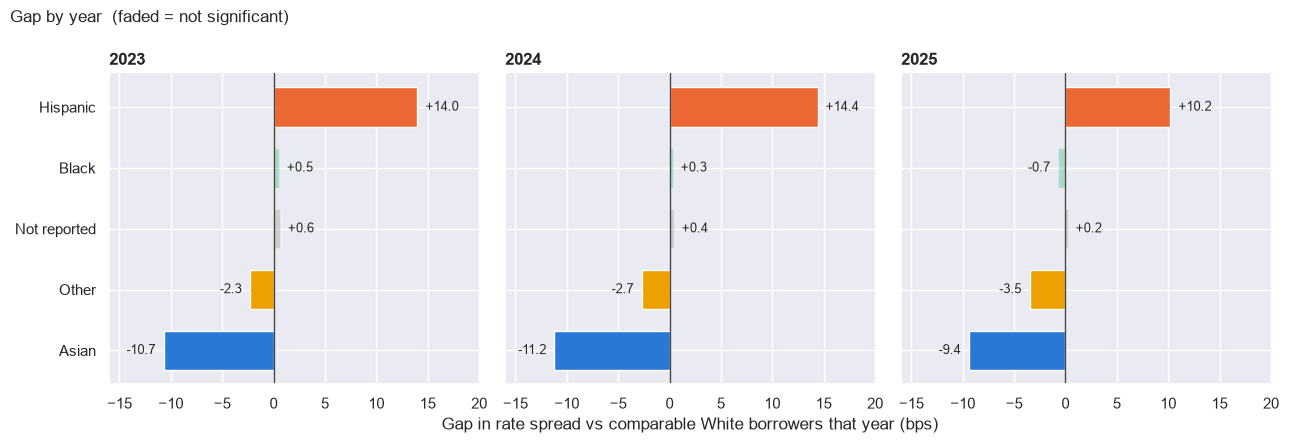

In [61]:
# Each group's gap in each year (one panel per year); faded bar = not significant at 0.05
show_groups = ["Hispanic", "Black", "Not reported", "Other", "Asian"]
years = ["2023", "2024", "2025"]

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5), sharey=True, sharex=True)
for ax, yr in zip(axes, years):
    for i, g in enumerate(show_groups[::-1]):                  # Hispanic at the top
        text = by_year[g][yr]                                   # e.g. "+14.0 (p = 0.004)"
        v = float(text.split(" ")[0])
        p = float(text.split("p = ")[1].rstrip(")"))
        ax.barh(i, v, color=group_colors[g], height=0.65, alpha=1 if p < 0.05 else 0.3)
        ax.text(v + (0.8 if v >= 0 else -0.8), i, f"{v:+.1f}", va="center",
                ha="left" if v >= 0 else "right", fontsize=9)
    ax.axvline(0, color="#444", lw=1)
    ax.set_title(yr, loc="left", fontsize=12, fontweight="bold")
    ax.set_xlim(-16, 20)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_yticks(range(len(show_groups)))
axes[0].set_yticklabels(show_groups[::-1])
axes[1].set_xlabel("Gap in rate spread vs comparable White borrowers that year (bps)")
fig.suptitle("Gap by year  (faded = not significant)", x=0.01, ha="left", fontsize=12)
plt.tight_layout()
plt.show()

In [62]:
# (b) Did each group's gap change across the three years?
# Add group x year interactions to the main model; F-test each group's 2024 and 2025 terms (vs. 2023)
inter_c, inter_r = fit(f"rate_spread ~ {X5} + race_group:activity_year", df, groups)
names = inter_c.model.exog_names
change = []
for label in ["Hispanic", "Black", "Asian", "Other", "Not reported"]:
    terms = [n for n in names if n.startswith(f"race_group[T.{label}]:")]
    ft = inter_r.f_test(restriction(names, terms))
    p = float(np.squeeze(ft.pvalue))
    change.append({"group": label, "F": round(float(np.squeeze(ft.fvalue)), 2),
                   "df": f"{int(ft.df_num)}, {int(ft.df_denom):,}", "p-value": round(p, 4),
                   f"changed at alpha {ALPHA_GROUP}?": "yes" if p < ALPHA_GROUP else "no"})
all_terms = [n for n in names if ":activity_year" in n]
ft_all = inter_r.f_test(restriction(names, all_terms))
print(f"All groups together: F = {float(np.squeeze(ft_all.fvalue)):.2f} on {int(ft_all.df_num)} and "
      f"{int(ft_all.df_denom):,} df, p = {float(np.squeeze(ft_all.pvalue)):.3g}")
del inter_c, inter_r
pd.DataFrame(change).set_index("group")

All groups together: F = 9.55 on 10 and 1,676 df, p = 1.31e-15


,F,df,p-value,changed at alpha 0.0125?
group,,,,
Hispanic,3.65,"2, 1,676",0.03,no
Black,12.00,"2, 1,676",0.00,yes
Asian,10.82,"2, 1,676",0.00,yes
Other,3.86,"2, 1,676",0.02,no
Not reported,0.65,"2, 1,676",0.52,no


### for the table for chow b
Columns:

F: how strong the evidence of a change is. Bigger means more likely it changed.
df (2, 1,676): 2 = the two years being compared with 2023 (2024 and 2025). 1,676 = based on the number of lenders.
p-value: the chance of seeing a change this big if the gap really stayed the same. Small means a real change.
changed at 0.0125?: "yes" if p is below our strict level of 0.0125.
Rows:

Hispanic (p = 0.03): no. The gap stayed about the same every year.
Black (p < 0.001): yes, but it only moved about 1 bp (from +0.4 to −0.7), so too small to matter.
Asian (p < 0.001): yes, but only about 1–2 bps (from −10.7 to −9.4), so too small to matter.
Other (p = 0.02): no.
Not reported (p = 0.52): no.
In short: no group's gap changed in a way that matters. The Hispanic gap was steady across all three years.

In [63]:
# (c) Chow test across groups: does ONE pricing model fit every group?
# Restricted: one model for all loans with no group dummies. Unrestricted: a separate model for each group.
rhs_no_group = X5.replace("race_group + ", "")
key = ["log_income", "log_loan", "points_pct", "loan_type[T.FHA]", "loan_type[T.VA]", "ltv_band[T.over 97%]"]

def fit_part(mask):
    part = df[mask].copy()
    for c in part.select_dtypes("category").columns:
        part[c] = part[c].cat.remove_unused_categories()
    return smf.ols(f"rate_spread ~ {rhs_no_group}", data=part).fit()

group_list = list(df["race_group"].cat.categories)        # White first
ssr, slopes = {}, {}
for g in group_list:
    r = fit_part(df["race_group"] == g)
    ssr[g], slopes[g] = r.ssr, {t: r.params.get(t, np.nan) for t in key}
    del r

pooled_all = fit_part(df["race_group"].notna())
k, G, n = len(pooled_all.params), len(group_list), len(df)
F_groups = ((pooled_all.ssr - sum(ssr.values())) / (k * (G - 1))) / (sum(ssr.values()) / (n - G * k))
print(f"All {G} groups: F = {F_groups:,.1f} on {k * (G - 1)} and {n - G * k:,} df, "
      f"p = {stats.f.sf(F_groups, k * (G - 1), n - G * k):.3g}")
del pooled_all

pairs = []                                                 # each group against White
for g in group_list[1:]:
    both = fit_part(df["race_group"].isin(["White", g]))
    k2, n2 = len(both.params), int(both.nobs)
    F = ((both.ssr - ssr["White"] - ssr[g]) / k2) / ((ssr["White"] + ssr[g]) / (n2 - 2 * k2))
    pairs.append({"group vs. White": g, "F": round(F, 1), "df": f"{k2}, {n2 - 2 * k2:,}",
                  "p-value": stats.f.sf(F, k2, n2 - 2 * k2)})
    del both
display(pd.DataFrame(pairs).set_index("group vs. White"))
pd.DataFrame(slopes).T.round(3)                             # how the key slopes differ by group

All 6 groups: F = 419.1 on 260 and 2,319,037 df, p = 0


,F,df,p-value
group vs. White,,,
Hispanic,"1,606.40","52, 1,455,719",0.00
Black,187.30,"52, 1,377,922",0.00
Asian,178.60,"52, 1,263,911",0.00
Other,43.80,"52, 1,248,034",0.00
Not reported,105.50,"52, 1,473,559",0.00


,log_income,log_loan,points_pct,loan_type[T.FHA],loan_type[T.VA],ltv_band[T.over 97%]
White,0.32,-0.38,-0.10,0.22,-0.57,0.36
Hispanic,0.52,-0.49,-0.09,0.20,-0.71,0.25
Black,0.57,-0.62,-0.10,0.31,-0.54,0.37
Asian,0.34,-0.36,-0.11,0.18,-0.57,0.32
Other,0.33,-0.44,-0.11,0.19,-0.63,0.37
Not reported,0.36,-0.46,-0.10,0.25,-0.56,0.36


### for table chow c (need looking again)
What it means:

Not every factor affects every group equally. Income, loan size and loan type work differently for Hispanic and Black borrowers.
So our +12.8 is an average. A Hispanic borrower's actual gap depends on their income, loan size and loan type.
Points are the exception: they work the same for everyone.


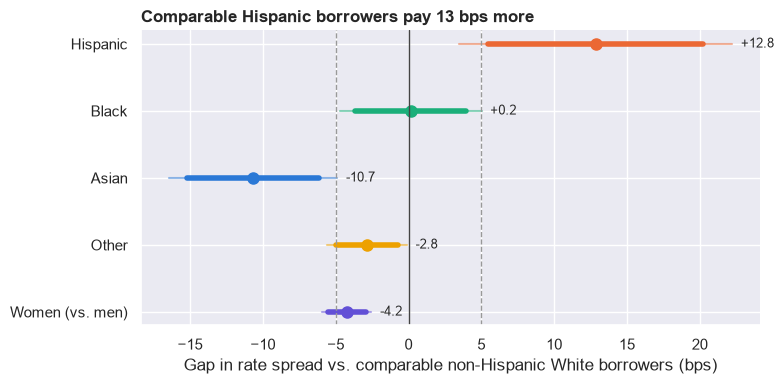

In [64]:
# Chart for the report: each gap with its 95% interval (thick) and its Bonferroni 98.75% interval (thin)
show = {"Hispanic": "race_group[T.Hispanic]", "Black": "race_group[T.Black]", "Asian": "race_group[T.Asian]",
        "Other": "race_group[T.Other]", "Women (vs. men)": "derived_sex[T.Female]"}
colors = {"Hispanic": "#eb6834", "Black": "#1baf7a", "Asian": "#2a78d6", "Other": "#eda100", "Women (vs. men)": "#6250d6"}
t95 = stats.t.ppf(0.975, n_lenders - 1)
t_bonf = stats.t.ppf(1 - ALPHA_GROUP / 2, n_lenders - 1)

fig, ax = plt.subplots(figsize=(8, 4))
for i, label in enumerate(reversed(list(show))):
    term = show[label]
    b, se = m["b"][term] * 100, m["se"][term] * 100
    ax.plot([b - t_bonf * se, b + t_bonf * se], [i, i], color=colors[label], lw=1.5, alpha=0.5)
    ax.plot([b - t95 * se, b + t95 * se], [i, i], color=colors[label], lw=4)
    ax.plot(b, i, "o", color=colors[label], ms=8)
    ax.text(b + t_bonf * se + 0.6, i, f"{b:+.1f}", va="center", fontsize=9)
ax.axvline(0, color="#444", lw=1)
for x in (-practical_bps, practical_bps):
    ax.axvline(x, color="#999", lw=1, ls="--")          # practical threshold
ax.set_yticks(range(len(show)))
ax.set_yticklabels(list(reversed(list(show))))
ax.set_xlabel("Gap in rate spread vs. comparable non-Hispanic White borrowers (bps)")
h = m["b"]["race_group[T.Hispanic]"] * 100
ax.set_title(f"Comparable Hispanic borrowers pay {h:.0f} bps more", loc="left", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("gap_intervals.png", dpi=200)
plt.show()

### above chart
Dot: what actually happened in our data (example: Hispanic +12.8).
Bar: where the gap could plausibly land if you allow for random noise in how loans get priced.

# Gap in each state

In [65]:
# Gap in each state: refit the main model separately for every state (state dummies dropped)
rhs_no_state = X5.replace(" + state_code", "")
show_groups = ["Hispanic", "Black", "Asian"]

rows = []
for st in df["state_code"].cat.categories:
    part = df[df["state_code"] == st].copy()
    for c in part.select_dtypes("category").columns:
        part[c] = part[c].cat.remove_unused_categories()
    c_res, r_res = fit(f"rate_spread ~ {rhs_no_state}", part, pd.factorize(part["lei"])[0])
    names = c_res.model.exog_names
    b, se, p = np.asarray(r_res.params), np.asarray(r_res.bse), np.asarray(r_res.pvalues)
    for g in show_groups:
        term = f"race_group[T.{g}]"
        if term in names:
            i = names.index(term)
            rows.append({"state": st, "group": g, "loans": int((part["race_group"] == g).sum()),
                         "gap (bps)": b[i] * 100, "se": se[i] * 100, "p-value": p[i]})
    del c_res, r_res

by_state = pd.DataFrame(rows)
by_state["significant"] = by_state["p-value"] < ALPHA_GROUP

# Table: gap in bps (* = significant at 0.0125), states sorted by the Hispanic gap
fmt = by_state.assign(cell=lambda t: t["gap (bps)"].round(1).astype(str) + np.where(t["significant"], "*", ""))
state_table = fmt.pivot(index="state", columns="group", values="cell")[show_groups]
state_table["Hispanic loans"] = by_state[by_state["group"] == "Hispanic"].set_index("state")["loans"]
order = by_state[by_state["group"] == "Hispanic"].sort_values("gap (bps)", ascending=False)["state"]
state_table = state_table.loc[order]
state_table

group,Hispanic,Black,Asian,Hispanic loans
state,,,,
MD,27.6*,3.5,-7.3*,15512
CT,17.7*,0.8,-5.4,10736
MA,17.4,1.4,-7.6*,12504
GA,16.4,-3.8,-17.3*,27559
VA,13.3*,-2.7,-5.9*,19093
NY,13.1*,-0.9,-1.0,21778
NJ,13.0*,0.9,-4.4,24265
DE,12.5,3.9,0.0,2193
NC,11.5,-7.1,-14.8*,24138


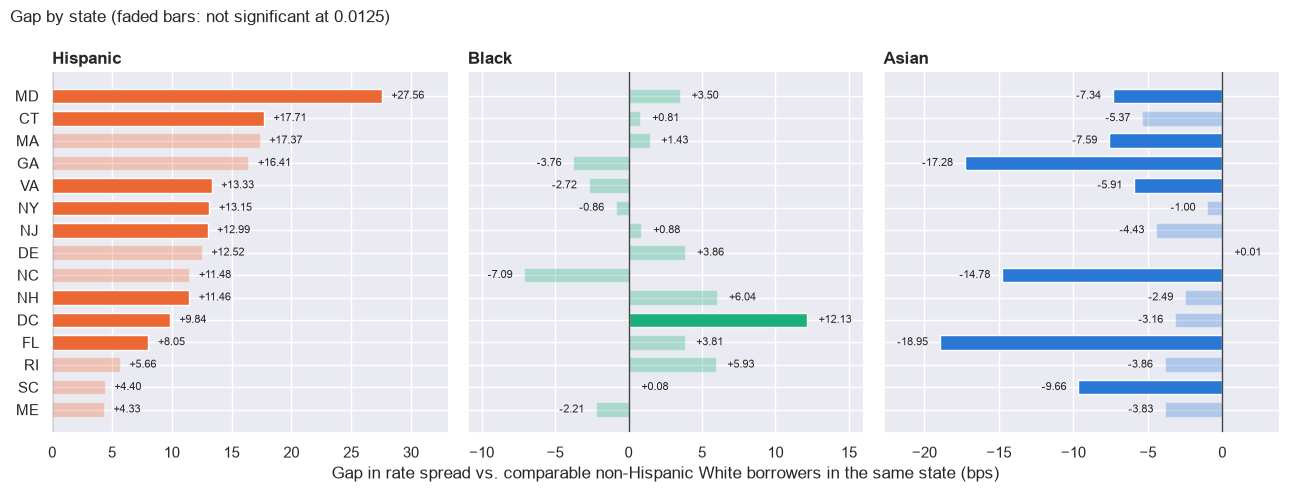

In [66]:
# Gap by state: one panel per group, faded bars = not significant at 0.0125
fig, axes = plt.subplots(1, 3, figsize=(13, 5), sharey=True)
for ax, g in zip(axes, show_groups):
    d = by_state[by_state["group"] == g].set_index("state").loc[order[::-1]]
    bars = ax.barh(d.index, d["gap (bps)"], color=group_colors[g], height=0.65)
    for bar, sig in zip(bars, d["significant"]):
        bar.set_alpha(1 if sig else 0.3)
    for i, v in enumerate(d["gap (bps)"]):
        ax.text(v + (0.8 if v >= 0 else -0.8), i, f"{v:+.2f}", va="center",
                ha="left" if v >= 0 else "right", fontsize=8)
    ax.axvline(0, color="#444", lw=1)
    ax.set_title(g, loc="left", fontweight="bold")
    ax.spines[["top", "right"]].set_visible(False)
    ax.margins(x=0.2)
axes[1].set_xlabel("Gap in rate spread vs. comparable non-Hispanic White borrowers in the same state (bps)")
fig.suptitle("Gap by state (faded bars: not significant at 0.0125)", x=0.01, ha="left", fontsize=12)
plt.tight_layout()
plt.show()

## above graph and table looks at the gap within each state: each group vs White borrowers in the same state.

In [67]:
# # Number of loans in each group, by state (sorted by total loans)
# counts = pd.crosstab(df["state_code"], df["race_group"])
# counts["Total"] = counts.sum(axis=1)
# counts = counts.sort_values("Total", ascending=False)
# counts.loc["All states"] = counts.sum()
# counts

In [68]:
# # Share of each group within each state (%)
# share = counts.drop(columns="Total").div(counts["Total"], axis=0) * 100
# share.round(1)

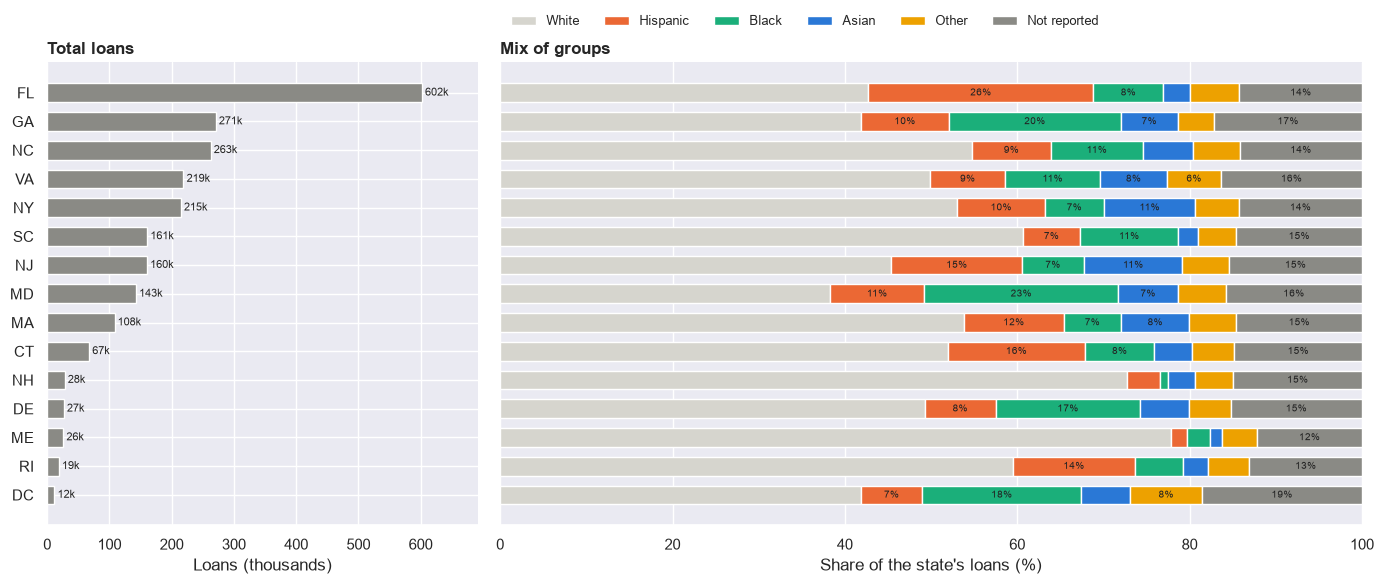

In [69]:
# Loans by state: total (left) and each group's share (right)
counts = pd.crosstab(df["state_code"], df["race_group"])
counts["Total"] = counts.sum(axis=1)
counts = counts.sort_values("Total", ascending=False)

colors = {"White": "#d6d5ce", **group_colors}            # White = light neutral (the baseline)
plot_groups = [g for g in colors if g in counts.columns]
share = counts[plot_groups].div(counts["Total"], axis=0) * 100
plot_order = share.index[::-1]                           # biggest state at the top

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), sharey=True,
                               gridspec_kw={"width_ratios": [1, 2]})

# Left: total loans per state
ax1.barh(plot_order, counts.loc[plot_order, "Total"] / 1000, color="#8a8a85", height=0.65)
for i, v in enumerate(counts.loc[plot_order, "Total"]):
    ax1.text(v / 1000 + 5, i, f"{v / 1000:,.0f}k", va="center", fontsize=8)
ax1.set_xlabel("Loans (thousands)")
ax1.set_title("Total loans", loc="left", fontweight="bold")
ax1.margins(x=0.15)

# Right: each group's share of the state's loans (100% stacked)
left = pd.Series(0.0, index=plot_order)
for g in plot_groups:
    vals = share.loc[plot_order, g]
    ax2.barh(plot_order, vals, left=left, color=colors[g], height=0.65,
             edgecolor="white", linewidth=1, label=g)
    for i, (v, l) in enumerate(zip(vals, left)):
        if v >= 6 and g != "White":                      # label only segments wide enough to read
            ax2.text(l + v / 2, i, f"{v:.0f}%", va="center", ha="center", fontsize=7.5, color="#222")
    left += vals
ax2.set_xlim(0, 100)
ax2.set_xlabel("Share of the state's loans (%)")
ax2.set_title("Mix of groups", loc="left", fontweight="bold")
ax2.legend(ncol=6, loc="lower left", bbox_to_anchor=(0, 1.05), frameon=False, fontsize=9)

for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

# is there a big difference across the income in each groups?

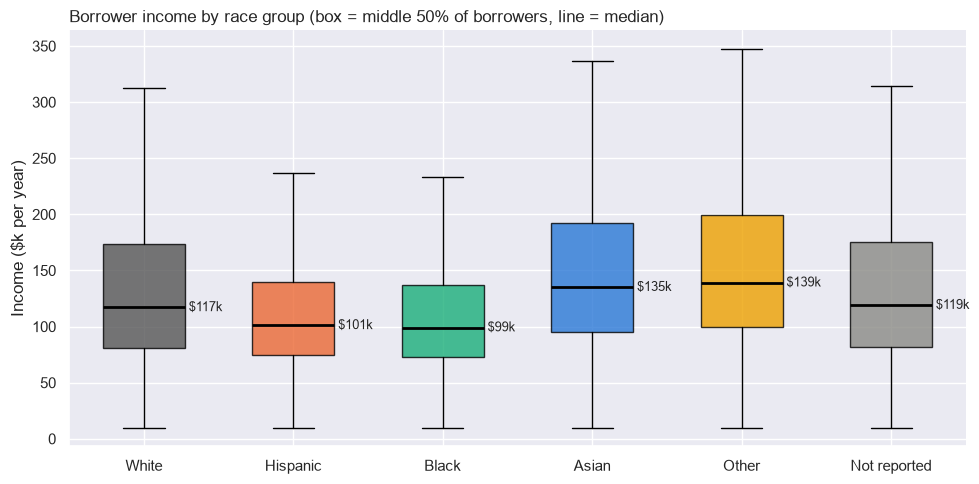

,count,25%,50%,75%,mean
race_group,,,,,
White,"1,125,079.00",81.00,117.00,174.00,149.00
Hispanic,"330,744.00",75.00,101.00,140.00,126.00
Black,"252,947.00",73.00,99.00,137.00,117.00
Asian,"138,936.00",95.00,135.00,192.00,165.00
Other,"123,059.00",100.00,139.00,199.00,168.00
Not reported,"348,584.00",82.00,119.00,175.00,152.00


In [70]:
# Income across race groups: the full spread, not just the average
order_g = ["White", "Hispanic", "Black", "Asian", "Other", "Not reported"]
colors = {"White": "#555555", **group_colors}
data = [df.loc[df["race_group"] == g, "income"] for g in order_g]

fig, ax = plt.subplots(figsize=(10, 5))
box = ax.boxplot(data, tick_labels=order_g, showfliers=False, patch_artist=True, widths=0.55,
                 medianprops=dict(color="black", lw=2))
for patch, g in zip(box["boxes"], order_g):
    patch.set_facecolor(colors[g]); patch.set_alpha(0.8)
for i, s in enumerate(data, start=1):
    ax.text(i + 0.3, s.median(), f"${s.median():,.0f}k", va="center", fontsize=9)
ax.set_ylabel("Income ($k per year)")
ax.set_title("Borrower income by race group (box = middle 50% of borrowers, line = median)", loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

# The numbers behind the chart
df.groupby("race_group", observed=True)["income"].describe(percentiles=[0.25, 0.5, 0.75])\
  .reindex(order_g)[["count", "25%", "50%", "75%", "mean"]].round(0)

## we see that black and hispanic likely to earn the same amount(they are in a simliar group). with asian and other likely be in the same category. we should pay attention to how we compare our data.

# what about share of income across income range in each group?

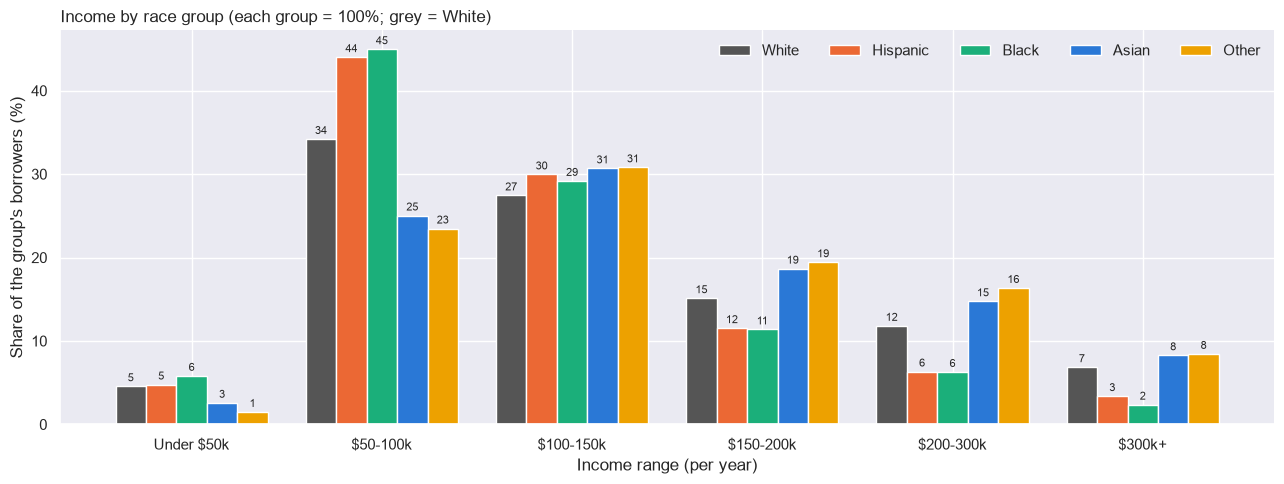

race_group,White,Hispanic,Black,Asian,Other
income,,,,,
Under $50k,4.57,4.77,5.82,2.59,1.49
$50-100k,34.20,44.02,44.97,25.03,23.47
$100-150k,27.44,29.95,29.18,30.68,30.81
$150-200k,15.12,11.54,11.38,18.66,19.43
$200-300k,11.82,6.33,6.28,14.76,16.35
$300k+,6.85,3.39,2.37,8.28,8.44


In [71]:
# Share of each group's borrowers in each income range (each group adds up to 100%)
order_g = ["White", "Hispanic", "Black", "Asian", "Other"]
colors = {"White": "#555555", **group_colors}
ranges = ["Under $50k", "$50-100k", "$100-150k", "$150-200k", "$200-300k", "$300k+"]
inc_range = pd.cut(df["income"], [0, 50, 100, 150, 200, 300, np.inf], labels=ranges, right=False)
counts = pd.crosstab(inc_range, df["race_group"]).reindex(index=ranges, columns=order_g)
shares = counts / counts.sum() * 100        # share of each group, so group size doesn't matter

x = np.arange(len(ranges))
w = 0.16
fig, ax = plt.subplots(figsize=(13, 5))
for j, g in enumerate(order_g):
    ax.bar(x + (j - 2) * w, shares[g], width=w, color=colors[g], label=g)
    for i, v in enumerate(shares[g]):
        ax.text(i + (j - 2) * w, v + 0.6, f"{v:.0f}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(ranges)
ax.set_xlabel("Income range (per year)"); ax.set_ylabel("Share of the group's borrowers (%)")
ax.set_title("Income by race group (each group = 100%; grey = White)", loc="left")
ax.legend(frameon=False, ncol=5)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

shares.round(2)

## okay, we are seeing something here, black and hispanic both have almost 50% of their total group earning less than 50-100k, this may help explain why they are having a higher rate than the baseline(white), but if we look back at our conclusion, hispanic is much more than black and why is that? 

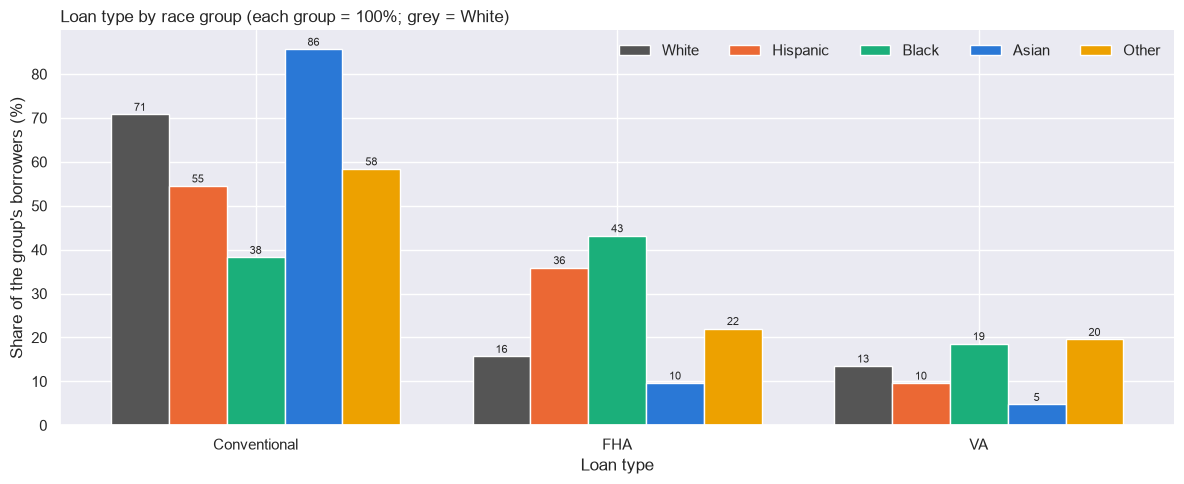

race_group,White,Hispanic,Black,Asian,Other
loan_type,,,,,
Conventional,70.80,54.50,38.20,85.70,58.40
FHA,15.70,35.90,43.20,9.60,22.00
VA,13.50,9.60,18.60,4.70,19.60


In [72]:
# Loan type mix of each group vs White (each group adds up to 100%)
order_g = ["White", "Hispanic", "Black", "Asian", "Other"]
colors = {"White": "#555555", **group_colors}
types = ["Conventional", "FHA", "VA"]
counts = pd.crosstab(df["loan_type"], df["race_group"]).reindex(index=types, columns=order_g)
shares = counts / counts.sum() * 100        # share of each group, so group size doesn't matter

x = np.arange(len(types))
w = 0.16
fig, ax = plt.subplots(figsize=(12, 5))
for j, g in enumerate(order_g):
    ax.bar(x + (j - 2) * w, shares[g], width=w, color=colors[g], label=g)
    for i, v in enumerate(shares[g]):
        ax.text(i + (j - 2) * w, v + 0.8, f"{v:.0f}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(types)
ax.set_xlabel("Loan type"); ax.set_ylabel("Share of the group's borrowers (%)")
ax.set_title("Loan type by race group (each group = 100%; grey = White)", loc="left")
ax.legend(frameon=False, ncol=5)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

shares.round(1)

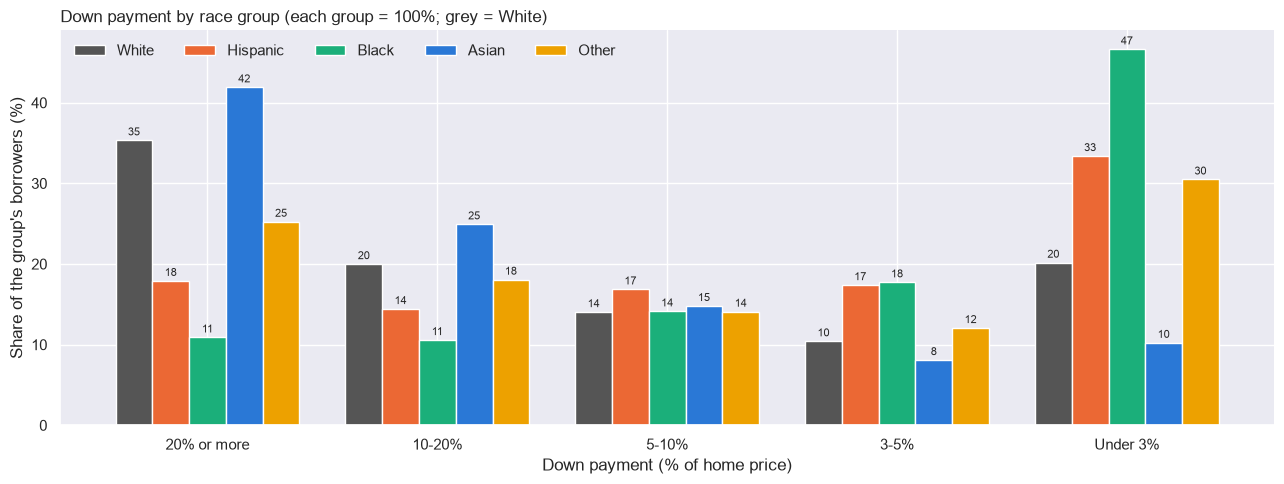

race_group,White,Hispanic,Black,Asian,Other
loan_to_value_ratio_calculated,,,,,
20% or more,35.30,17.90,10.90,41.90,25.30
10-20%,20.00,14.40,10.60,24.90,18.10
5-10%,14.00,16.90,14.10,14.80,14.10
3-5%,10.40,17.40,17.70,8.10,12.10
Under 3%,20.20,33.40,46.60,10.20,30.50


In [73]:
# Down payment of each group vs White (each group adds up to 100%)
order_g = ["White", "Hispanic", "Black", "Asian", "Other"]
colors = {"White": "#555555", **group_colors}
ranges = ["20% or more", "10-20%", "5-10%", "3-5%", "Under 3%"]
down = pd.cut(df["loan_to_value_ratio_calculated"], [0, 80, 90, 95, 97, np.inf], labels=ranges)   # down payment = 100 - LTV
counts = pd.crosstab(down, df["race_group"]).reindex(index=ranges, columns=order_g)
shares = counts / counts.sum() * 100        # share of each group, so group size doesn't matter

x = np.arange(len(ranges))
w = 0.16
fig, ax = plt.subplots(figsize=(13, 5))
for j, g in enumerate(order_g):
    ax.bar(x + (j - 2) * w, shares[g], width=w, color=colors[g], label=g)
    for i, v in enumerate(shares[g]):
        ax.text(i + (j - 2) * w, v + 0.6, f"{v:.0f}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(ranges)
ax.set_xlabel("Down payment (% of home price)"); ax.set_ylabel("Share of the group's borrowers (%)")
ax.set_title("Down payment by race group (each group = 100%; grey = White)", loc="left")
ax.legend(frameon=False, ncol=5)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

shares.round(1)

## okay this still doesn't explain much, down payment matters because it helps lower the rate. we should look into under 3%, is it VA?

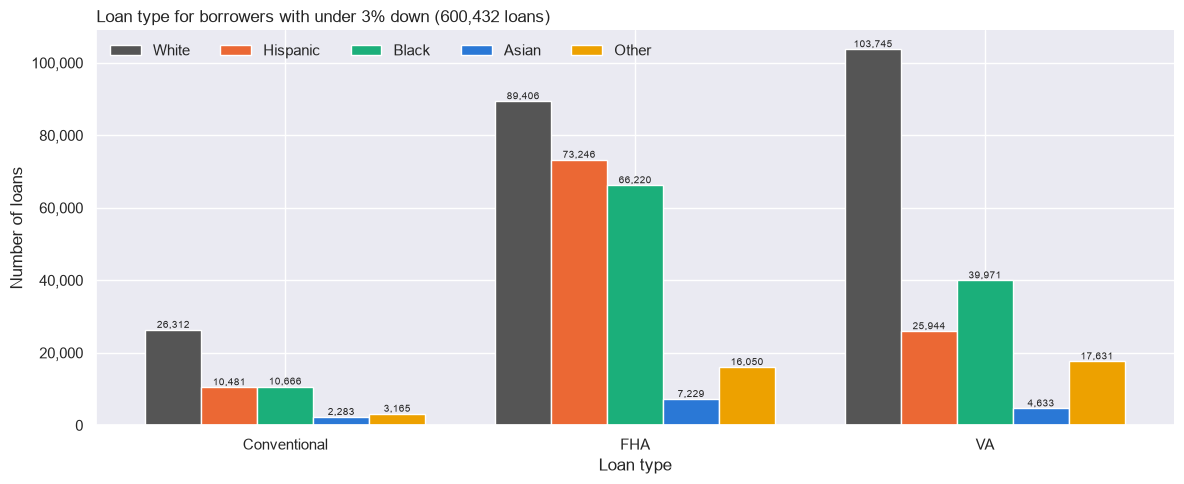

count                              share (%)                 \
race_group     White Hispanic  Black Asian  Other     White Hispanic Black   
loan_type                                                                    
Conventional   26312    10481  10666  2283   3165     12.00     9.60  9.10   
FHA            89406    73246  66220  7229  16050     40.70    66.80 56.70   
VA            103745    25944  39971  4633  17631     47.30    23.70 34.20   

                          
race_group   Asian Other  
loan_type                 
Conventional 16.10  8.60  
FHA          51.10 43.60  
VA           32.80 47.90

In [74]:
# Borrowers with under 3% down: how many loans of each type in each group (counts)
order_g = ["White", "Hispanic", "Black", "Asian", "Other"]
colors = {"White": "#555555", **group_colors}
types = ["Conventional", "FHA", "VA"]
low = df[df["loan_to_value_ratio_calculated"] > 97]
counts = pd.crosstab(low["loan_type"], low["race_group"]).reindex(index=types, columns=order_g)

x = np.arange(len(types))
w = 0.16
fig, ax = plt.subplots(figsize=(12, 5))
for j, g in enumerate(order_g):
    ax.bar(x + (j - 2) * w, counts[g], width=w, color=colors[g], label=g)
    for i, v in enumerate(counts[g]):
        ax.text(i + (j - 2) * w, v, f"{v:,.0f}", ha="center", va="bottom", fontsize=7)
ax.set_xticks(x); ax.set_xticklabels(types)
ax.set_xlabel("Loan type"); ax.set_ylabel("Number of loans")
ax.set_title(f"Loan type for borrowers with under 3% down ({len(low):,} loans)", loc="left")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.legend(frameon=False, ncol=5)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

# Count and share together
summary = pd.concat({"count": counts, "share (%)": (counts / counts.sum() * 100).round(1)}, axis=1)
summary

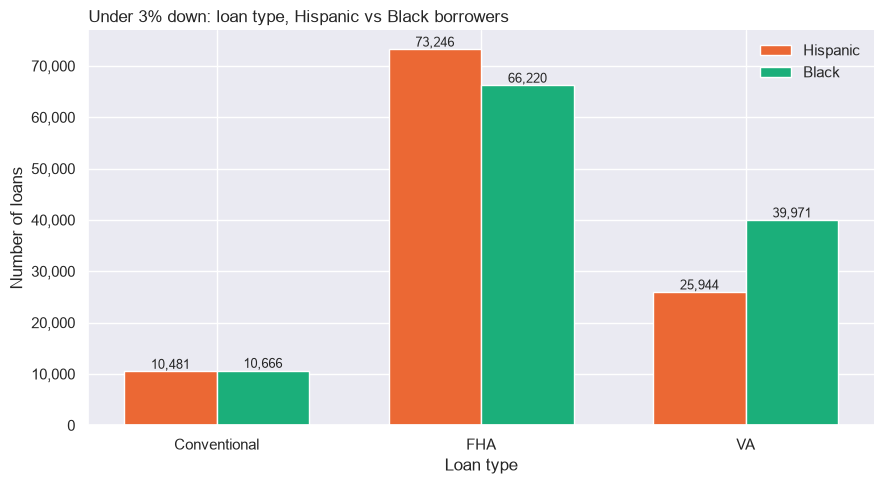

count        share (%)      
race_group   Hispanic  Black  Hispanic Black
loan_type                                   
Conventional    10481  10666      9.60  9.10
FHA             73246  66220     66.80 56.70
VA              25944  39971     23.70 34.20

In [75]:
# Under 3% down: loan type count, Hispanic vs Black
order_g = ["Hispanic", "Black"]
types = ["Conventional", "FHA", "VA"]
low = df[df["loan_to_value_ratio_calculated"] > 97]
counts = pd.crosstab(low["loan_type"], low["race_group"]).reindex(index=types, columns=order_g)

x = np.arange(len(types))
w = 0.35
fig, ax = plt.subplots(figsize=(9, 5))
for j, g in enumerate(order_g):
    ax.bar(x + (j - 0.5) * w, counts[g], width=w, color=group_colors[g], label=g)
    for i, v in enumerate(counts[g]):
        ax.text(i + (j - 0.5) * w, v, f"{v:,.0f}", ha="center", va="bottom", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(types)
ax.set_xlabel("Loan type"); ax.set_ylabel("Number of loans")
ax.set_title("Under 3% down: loan type, Hispanic vs Black borrowers", loc="left")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

# Count and share within each group
pd.concat({"count": counts, "share (%)": (counts / counts.sum() * 100).round(1)}, axis=1)

## not much VA in black group but is slightly higher than hispanic, but still doesn't explain it. 

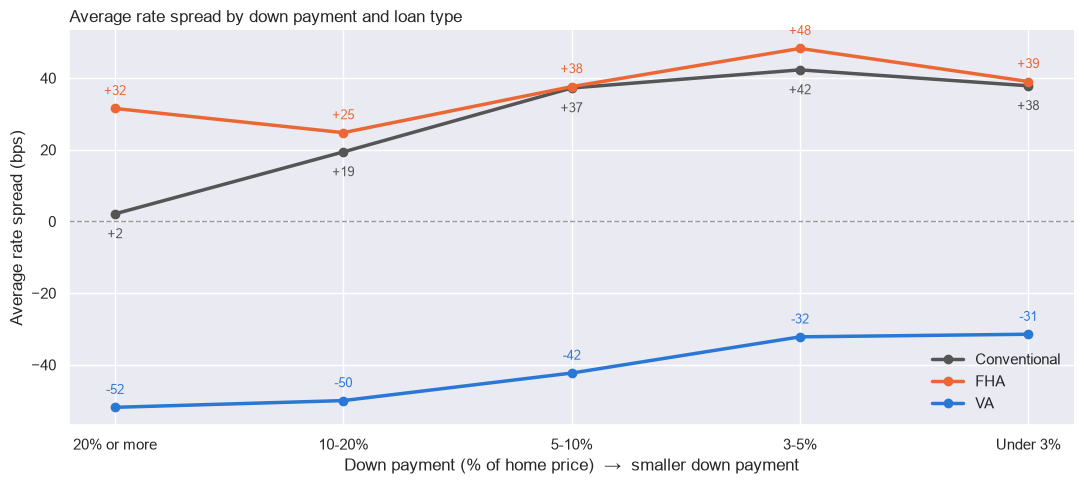

loan_type,Conventional,FHA,VA
down,,,
20% or more,2.10,31.50,-51.90
10-20%,19.40,24.80,-50.00
5-10%,37.20,37.60,-42.30
3-5%,42.30,48.30,-32.20
Under 3%,37.80,39.00,-31.50


In [76]:
# How does down payment change the rate spread, for each loan type?
ranges = ["20% or more", "10-20%", "5-10%", "3-5%", "Under 3%"]
down = pd.cut(df["loan_to_value_ratio_calculated"], [0, 80, 90, 95, 97, np.inf], labels=ranges)   # down payment = 100 - LTV
types = {"Conventional": "#555555", "FHA": "#eb6834", "VA": "#2a78d6"}
avg = (df.assign(down=down, spread_bps=df["rate_spread"] * 100)
         .groupby(["down", "loan_type"], observed=True)["spread_bps"].mean().unstack()
         .reindex(index=ranges, columns=list(types)))

fig, ax = plt.subplots(figsize=(11, 5))
for t, c in types.items():
    ax.plot(ranges, avg[t], marker="o", lw=2.5, color=c, label=t)
    for i, v in enumerate(avg[t]):
        below = t == "Conventional"                        # put Conventional labels under the line so they don't overlap FHA
        ax.text(i, v - 4 if below else v + 3, f"{v:+.0f}", ha="center", va="top" if below else "bottom",
                fontsize=9, color=c)
ax.axhline(0, color="#999", lw=1, ls="--")
ax.set_xlabel("Down payment (% of home price)  →  smaller down payment")
ax.set_ylabel("Average rate spread (bps)")
ax.set_title("Average rate spread by down payment and loan type", loc="left")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

avg.round(1)

## Down payment
A smaller down payment means more risk for the lender and a higher price. Hispanic borrowers put down less than White borrowers (33% put down under 3%), and Asian borrowers put down the most (42% put down 20% or more). This explains part of the raw gap. But Black borrowers put down even less than Hispanic borrowers (47% under 3%) and still pay less. Why? Next, we check which loans the under-3% borrowers use.


##  i see that the graph explain the asian part well but if we look at black vs hispanic we see that hispanic actually does better than black but why is black so close with the baseline but hispanic is not??? Unless the lender for hispanic is finding more expensive lender?

In [77]:
# Same-lender comparison: add lender fixed effects to the main model (X5)
# Each borrower is now compared only with borrowers at the SAME lender.
# If a group's gap shrinks, part of it came from WHICH lenders that group uses.
from patsy import dmatrices

y, X = dmatrices(f"rate_spread ~ {X5}", data=df, return_type="dataframe")
X = X.drop(columns="Intercept")
assert len(y) == len(df), "rows were dropped; check for missing values"
names = list(X.columns)
Xv, yv = X.to_numpy(dtype=float, copy=True), y.to_numpy(dtype=float, copy=True).ravel()
del X, y

# Remove each lender's average from every variable (same result as 1,677 lender dummies, far less memory)
n_g = np.bincount(groups)
def demean(a):
    return a - (np.bincount(groups, weights=a) / n_g)[groups]
yv = demean(yv)
for j in range(Xv.shape[1]):
    Xv[:, j] = demean(Xv[:, j])

b = np.linalg.lstsq(Xv, yv, rcond=None)[0]
e = yv - Xv @ b

# Standard errors clustered by lender
bread = np.linalg.pinv(Xv.T @ Xv)
S = np.vstack([np.bincount(groups, weights=Xv[:, j] * e) for j in range(Xv.shape[1])]).T
G, N, K = len(n_g), len(e), Xv.shape[1] + len(n_g)
V = bread @ (S.T @ S) @ bread * G / (G - 1) * (N - 1) / (N - K)
se = np.sqrt(np.diag(V))
del Xv, yv, e, S

rows = []
for g in ["Hispanic", "Black", "Asian", "Other", "Not reported"]:
    term = f"race_group[T.{g}]"
    i = names.index(term)
    p = 2 * stats.t.sf(abs(b[i] / se[i]), G - 1)
    rows.append({"group": g,
                 "main model (bps)": round(m["b"][term] * 100, 1),
                 "same lender (bps)": round(b[i] * 100, 1),
                 "p-value (same lender)": "< 0.001" if p < 0.001 else round(p, 3),
                 "share explained by lender choice": f"{(1 - b[i] / m['b'][term]) * 100:.0f}%"
                     if abs(m["b"][term]) * 100 >= 5 else "—"})     # only meaningful for gaps over 5 bps
same_lender = pd.DataFrame(rows).set_index("group")
same_lender

,main model (bps),same lender (bps),p-value (same lender),share explained by lender choice
group,,,,
Hispanic,12.80,5.30,< 0.001,58%
Black,0.20,2.70,0.00,—
Asian,-10.70,-3.70,0.00,65%
Other,-2.80,0.20,0.45,—
Not reported,0.40,-0.20,0.67,—


# we build a model and see what if everyone have the same lender how much difference would it be with the baseline

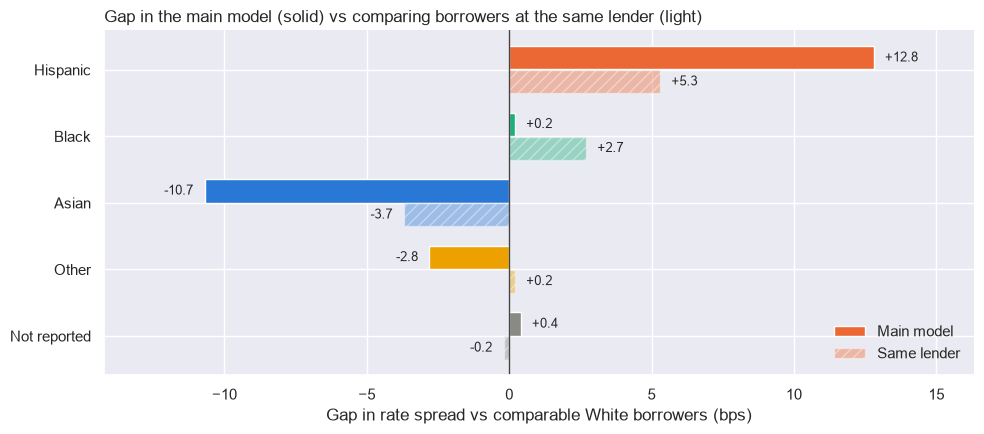

In [78]:
# Chart: gap in the main model vs gap at the same lender
show = ["Hispanic", "Black", "Asian", "Other", "Not reported"]
t = same_lender.loc[show]
y_pos = np.arange(len(show))[::-1]
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(y_pos + 0.18, t["main model (bps)"], height=0.35, color=[group_colors[g] for g in show], label="Main model")
ax.barh(y_pos - 0.18, t["same lender (bps)"], height=0.35, color=[group_colors[g] for g in show], alpha=0.4,
        hatch="///", edgecolor="white", label="Same lender")
for yp, a, c in zip(y_pos, t["main model (bps)"], t["same lender (bps)"]):
    ax.text(a + (0.4 if a >= 0 else -0.4), yp + 0.18, f"{a:+.1f}", va="center", ha="left" if a >= 0 else "right", fontsize=9)
    ax.text(c + (0.4 if c >= 0 else -0.4), yp - 0.18, f"{c:+.1f}", va="center", ha="left" if c >= 0 else "right", fontsize=9)
ax.set_yticks(y_pos); ax.set_yticklabels(show)
ax.axvline(0, color="#444", lw=1)
ax.set_xlabel("Gap in rate spread vs comparable White borrowers (bps)")
ax.set_title("Gap in the main model (solid) vs comparing borrowers at the same lender (light)", loc="left")
ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
ax.margins(x=0.15)
plt.tight_layout()
plt.show()

## Hispanic group likely getting more expensive loan compare with the rest
Main model: borrowers from all different banks, compared together. The gap is 12.8.
Light bar: as if everyone got their loan at the same bank. The gap is 5.3.
"One possible explanation is that some borrowers compare more lenders before choosing one. HMDA does not record how many lenders a borrower contacted, so we cannot test this."

## conclusion
"Asian borrowers pay less because they have stronger financial profiles (larger down payments, higher incomes, mostly conventional loans) and tend to use lower-cost lenders. Hispanic borrowers pay more partly because of smaller down payments and heavier use of FHA loans, and partly because they tend to use higher-cost lenders. Black borrowers have similarly weak down payments but offset this with more VA loans and lower-cost lenders. About 5 bps of the Hispanic gap remains unexplained, which may reflect unmeasured factors such as credit scores or how much borrowers shop around.

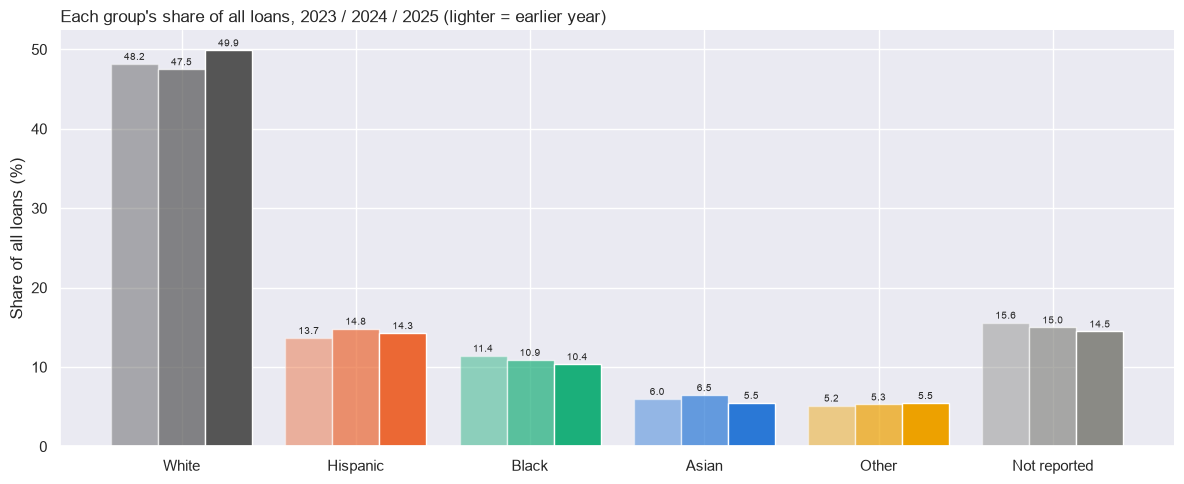

race_group,White,Hispanic,Black,Asian,Other,Not reported
activity_year,,,,,,
2023,48.20,13.70,11.40,6.00,5.20,15.60
2024,47.50,14.80,10.90,6.50,5.30,15.00
2025,49.90,14.30,10.40,5.50,5.50,14.50


In [79]:
# Each group's share of all loans, by year
order_g = ["White", "Hispanic", "Black", "Asian", "Other", "Not reported"]
colors = {"White": "#555555", **group_colors}
shares = pd.crosstab(df["activity_year"], df["race_group"], normalize="index").mul(100)[order_g]
years = [str(y) for y in shares.index]

x = np.arange(len(order_g))
w = 0.27
fig, ax = plt.subplots(figsize=(12, 5))
for j, (yr, alpha) in enumerate(zip(years, [0.45, 0.7, 1.0])):     # lighter = earlier year
    vals = shares.iloc[j]
    ax.bar(x + (j - 1) * w, vals, width=w, color=[colors[g] for g in order_g], alpha=alpha,
           edgecolor="white", label=yr)
    for i, v in enumerate(vals):
        ax.text(i + (j - 1) * w, v + 0.5, f"{v:.1f}", ha="center", fontsize=7)
ax.set_xticks(x); ax.set_xticklabels(order_g)
ax.set_ylabel("Share of all loans (%)")
ax.set_title("Each group's share of all loans, 2023 / 2024 / 2025 (lighter = earlier year)", loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

shares.round(1)

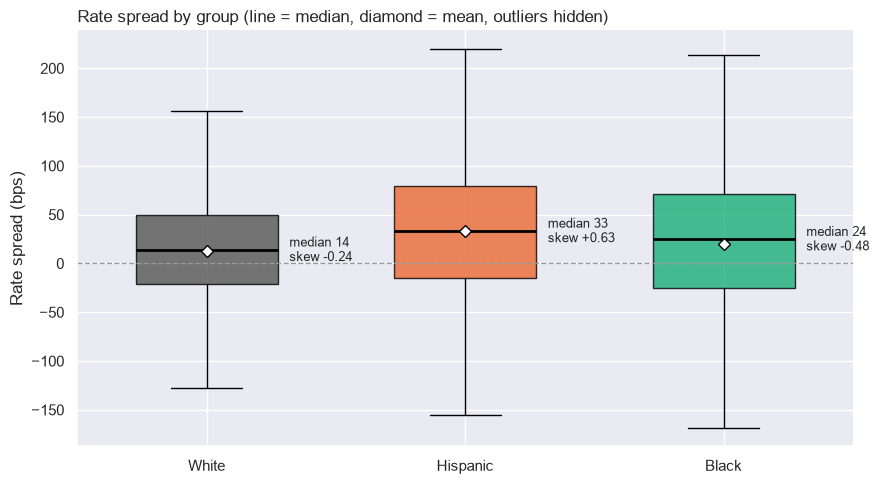

In [80]:
# Rate spread for White, Hispanic and Black borrowers: spread and skew
show = ["White", "Hispanic", "Black"]
colors = {"White": "#555555", **group_colors}
data = [df.loc[df["race_group"] == g, "rate_spread"] * 100 for g in show]

fig, ax = plt.subplots(figsize=(9, 5))
box = ax.boxplot(data, tick_labels=show, showfliers=False, patch_artist=True, widths=0.55,
                 showmeans=True, meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor="black"),
                 medianprops=dict(color="black", lw=2))
for patch, g in zip(box["boxes"], show):
    patch.set_facecolor(colors[g]); patch.set_alpha(0.8)
for i, s in enumerate(data, start=1):
    ax.text(i + 0.32, s.median(), f"median {s.median():.0f}\nskew {s.skew():+.2f}", va="center", fontsize=9)
ax.axhline(0, color="#999", lw=1, ls="--")
ax.set_ylabel("Rate spread (bps)")
ax.set_title("Rate spread by group (line = median, diamond = mean, outliers hidden)", loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [81]:
counts = df["race_group"].value_counts().to_frame("loans")
counts.loc["Total"] = counts["loans"].sum()
counts

,loans
race_group,
White,1125079
Not reported,348584
Hispanic,330744
Black,252947
Asian,138936
Other,123059
Total,2319349


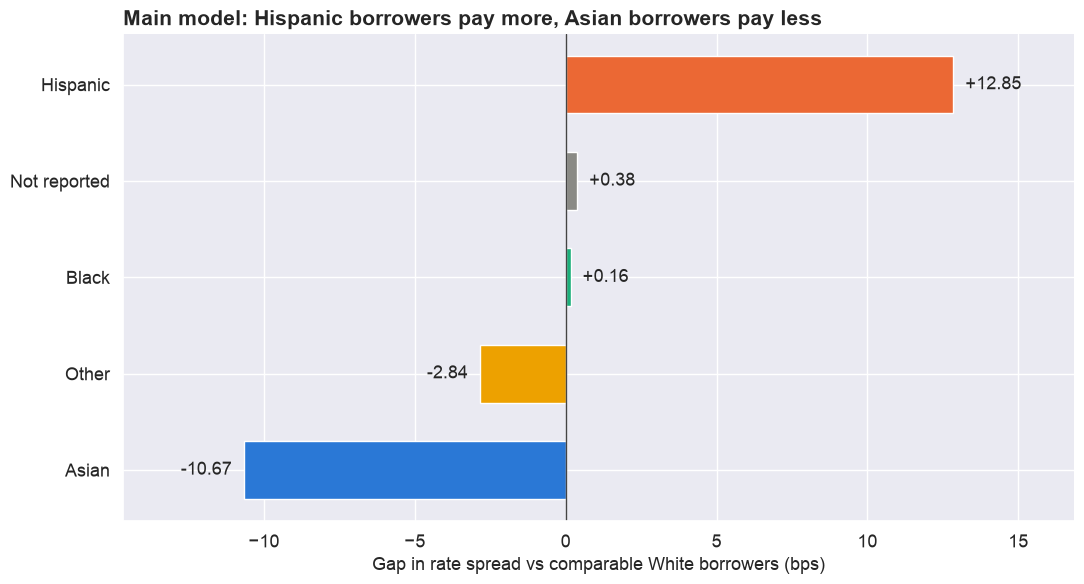

In [82]:
# Main model (X5): each group's gap vs comparable non-Hispanic White borrowers
show = ["Hispanic", "Black", "Asian", "Other", "Not reported"]
gaps = pd.Series({g: m["b"][f"race_group[T.{g}]"] * 100 for g in show}).sort_values()

fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(gaps.index, gaps.values, color=[group_colors[g] for g in gaps.index], height=0.6)
for i, v in enumerate(gaps.values):
    ax.text(v + (0.4 if v >= 0 else -0.4), i, f"{v:+.2f}", va="center",
            ha="left" if v >= 0 else "right", fontsize=13)
ax.axvline(0, color="#444", lw=1)
ax.set_xlim(gaps.min() - 4, gaps.max() + 4)
ax.tick_params(labelsize=13)
ax.set_xlabel("Gap in rate spread vs comparable White borrowers (bps)", fontsize=13)
ax.set_title("Main model: Hispanic borrowers pay more, Asian borrowers pay less",
             loc="left", fontweight="bold", fontsize=15)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

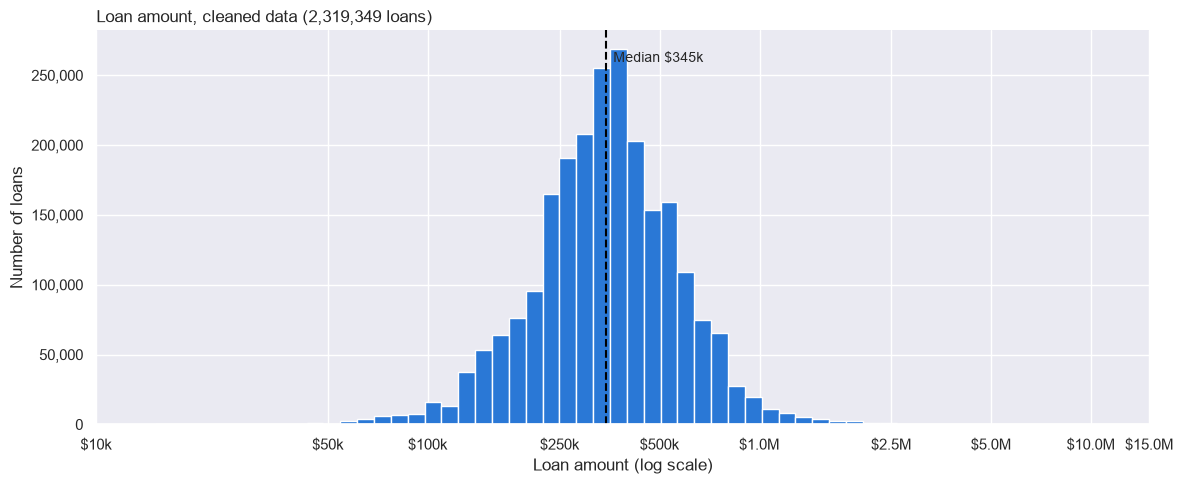

In [85]:
# Histogram of loan amount (cleaned data), x-axis up to $15M
s = df["loan_amount"]

fig, ax = plt.subplots(figsize=(12, 5))
bins = np.logspace(np.log10(s.min()), np.log10(15_000_000), 60)   # log bins up to $15M
ax.hist(s, bins=bins, color="#2a78d6", edgecolor="white")
ax.set_xscale("log")
ax.set_xlim(s.min(), 15_000_000)
ax.set_xticks([10_000, 50_000, 100_000, 250_000, 500_000, 1_000_000, 2_500_000, 5_000_000, 10_000_000, 15_000_000])
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"${x/1e6:,.1f}M" if x >= 1e6 else f"${x/1e3:,.0f}k"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:,.0f}"))

med = s.median()
ax.axvline(med, color="black", lw=1.5, ls="--")
ax.text(med * 1.05, ax.get_ylim()[1] * 0.92, f"Median ${med/1e3:,.0f}k", fontsize=10)

ax.set_xlabel("Loan amount (log scale)")
ax.set_ylabel("Number of loans")
ax.set_title(f"Loan amount, cleaned data ({len(s):,} loans)", loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
